# Cobertura eléctrica rural y rendimiento en Saber 11 (Colombia)
## Cuaderno ACA1 — Etapas 1 y 2 de la ruta del proyecto (CRISP-DM: comprensión del negocio, comprensión de los datos y preparación de los datos)

**Especialización en Analítica de Datos — CUN.** Proyecto de grado, Avance 1 (versión `v0.1`).

**Autores:** Diego Alejandro Prada · Leidy Adriana Motta Molina · Cristian Stiven Quitian Rojas
**Director:** Juan Pablo Morales Arias

Este cuaderno se ejecuta de principio a fin sin intervención manual y con semilla fija. **Todas las cifras, tablas y figuras del
documento de grado salen de aquí**: se guardan en `results/tables/` (incluido `cifras.json`), `results/figures/` (PNG a 300 dpi y SVG) y `results/experiments.csv`.

| Etapa de la ruta | Fase CRISP-DM | Sección del cuaderno |
|---|---|---|
| 1. Problema de negocio · Estado del arte · Adquisición de datos | 1. Comprensión del negocio / 2. Comprensión de los datos | Secciones 1–3 |
| 2. Proceso ETL · EDA multivariado · Ingeniería de características | 3. Preparación de los datos (y 2. Comprensión) | Secciones 4–8 |

In [1]:
# 0. Configuración del entorno -----------------------------------------------------------
# En Google Colab: clona el repositorio y entra en él (las celdas siguientes detectan la raíz automáticamente).
import os, sys, subprocess
EN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/USUARIO/energia-rural-saber11.git"   # <- reemplazar por la URL real del repositorio
if EN_COLAB and not os.path.exists("energia-rural-saber11"):
    subprocess.run(["git", "clone", REPO_URL], check=True)
if EN_COLAB:
    os.chdir("energia-rural-saber11")

In [2]:
import json, hashlib, random, platform, time, datetime as dt, warnings
T0 = time.time()
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import stats
import sklearn
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore", category=FutureWarning)

# Semilla fija (reproducibilidad)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
RNG = np.random.default_rng(SEED)

# Rutas
ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RAW_ICFES = ROOT / "data/raw/icfes"
RAW_UPME = ROOT / "data/raw/upme"
PROCESSED = ROOT / "data/processed"
FIG = ROOT / "results/figures"
TAB = ROOT / "results/tables"
for p in (PROCESSED, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)

# Modo de adquisición: "congelado" usa las copias fechadas del repositorio (verificando su huella SHA-256);
# "api" vuelve a descargar desde datos.gov.co y UPME (los resultados pueden cambiar si las fuentes se actualizan).
MODO_ADQUISICION = os.environ.get("MODO_ADQUISICION", "congelado")

# Estilo de figuras: marcas delgadas, rejilla recesiva, paleta validada (azul, naranja, aqua)
C1, C2, C3, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10, "axes.titlesize": 11,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold", "legend.frameon": False,
})

CIFRAS = {}          # todas las cifras que cita el documento
def registrar(clave, valor):
    """Guarda una cifra calculada para que el documento la cite sin escribirla a mano."""
    if isinstance(valor, (np.floating, np.integer)):
        valor = valor.item()
    CIFRAS[clave] = valor
    return valor

def guardar_tabla(df, nombre, index=False):
    df.to_csv(TAB / f"{nombre}.csv", index=index, encoding="utf-8-sig")
    return df

def guardar_fig(fig, nombre):
    fig.savefig(FIG / f"{nombre}.png", dpi=300, bbox_inches="tight", facecolor="white")
    fig.savefig(FIG / f"{nombre}.svg", bbox_inches="tight", facecolor="white")
    return fig

try:
    display  # disponible en Jupyter / Colab
except NameError:
    def display(x):
        print(x.to_string() if hasattr(x, "to_string") else x)

versiones = {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__,
             "scipy": scipy.__version__, "scikit-learn": sklearn.__version__,
             "matplotlib": matplotlib.__version__, "seaborn": sns.__version__}
registrar("versiones", versiones)
print("Raíz del proyecto:", ROOT)
print("Modo de adquisición:", MODO_ADQUISICION, "| Semilla:", SEED)
print(versiones)

Raíz del proyecto: /home/claude/energia-rural-saber11
Modo de adquisición: congelado | Semilla: 42
{'python': '3.13.16', 'pandas': '3.0.5', 'numpy': '2.5.3', 'scipy': '1.18.1', 'scikit-learn': '1.9.1', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


## 1. Etapa 1 · Problema de negocio (CRISP-DM 1: comprensión del negocio)

**Problema.** Los estudiantes de sedes rurales obtienen en Saber 11 puntajes sistemáticamente más bajos que los urbanos. La explicación
habitual (nivel socioeconómico) deja por fuera una condición material básica: el acceso a energía eléctrica, que condiciona la iluminación,
el uso de computadores, la conectividad y el tiempo de estudio en casa.

**Pregunta de investigación.** ¿Cuál es la relación entre la cobertura de energía eléctrica rural y el rendimiento en Saber 11 de los
estudiantes de sedes rurales de Colombia en el periodo 2019–2022?

**Variable objetivo (definida en este avance).** `punt_global_rural`: puntaje global promedio de Saber 11 (escala 0–500) de los estudiantes
de sedes educativas rurales de calendario A, por **municipio y año**.

**Variable explicativa principal.** `icee_rural`: Índice de Cobertura de Energía Eléctrica de la zona rural del municipio (UPME), en %.

**Unidad de análisis.** Municipio–año (panel 2019, 2020 y 2022). **Enfoque:** descriptivo–diagnóstico (rama analítica de la ruta).

**Criterio de éxito de negocio.** Entregar al MEN, la UPME y las secretarías de educación una medición verificable de (i) cuánto difiere el
rendimiento rural entre municipios con distinta cobertura eléctrica, (ii) si la diferencia se sostiene al controlar por condiciones
socioeconómicas y (iii) en qué territorios conviene priorizar la electrificación ligada a sedes educativas.

## 2. Etapa 1 · Estado del arte (resumen operativo)
El estado del arte completo está en el documento (sección 6.1). Para el análisis de datos se derivan cuatro decisiones:
1. La literatura (Lipscomb et al., 2013; Khandker et al., 2012) asocia electrificación con más tiempo de estudio y matrícula, pero con efectos
   **condicionados** a inversiones complementarias (Lenz et al., 2017) → se incluyen covariables de contexto (internet, computador, estrato).
2. La brecha rural–urbana en Saber 11 está documentada (Rodríguez Gómez et al., 2024; LEE, 2025) → se calcula también la brecha urbano–rural.
3. La pandemia es un quiebre estructural (Ballesteros-Alfonso y Gómez-Velasco, 2022) → los hallazgos se revisan por año (2019 pre, 2020 pandemia, 2022 post).
4. El vacío: ningún estudio cruza el ICEE rural municipal con Saber 11 → la integración por código DIVIPOLA es el aporte original.

## 3. Etapa 1 · Adquisición de datos (CRISP-DM 2: comprensión de los datos)

| Fuente | Conjunto | Acceso | Licencia |
|---|---|---|---|
| ICFES vía datos.gov.co | *Resultados únicos Saber 11* (`kgxf-xxbe`), periodos 20194 (2019) y 20224 (2022) | API SODA (Socrata) | CC BY-SA 4.0 |
| ICFES vía datos.gov.co | *Saber 11° 2020-2* (`rnvb-vnyh`), periodo 20204 (2020) | API SODA (Socrata) | CC BY-SA 4.0 |
| UPME | Anexo 1 Cálculo ICEE 2019–2022; Anexos ICEE 2023 y 2024 por municipio | Descarga directa (.xlsx) | Información pública (Ley 1712 de 2014), citando la fuente |

Solo se descargan las 23 columnas necesarias. **No se descargan** la fecha de nacimiento, el tipo de documento ni nombres: el identificador
`estu_consecutivo` es un código seudonimizado del ICFES. Cada archivo se guarda con la fecha de descarga en el nombre y su huella SHA-256 en
`data/raw/manifiesto_descargas.csv`.

In [3]:
COLUMNAS_ICFES = [
    "periodo", "estu_consecutivo", "cole_area_ubicacion", "cole_naturaleza", "cole_calendario", "cole_jornada",
    "cole_cod_dane_sede", "cole_cod_mcpio_ubicacion", "cole_cod_depto_ubicacion", "cole_mcpio_ubicacion",
    "cole_depto_ubicacion", "estu_genero", "fami_estratovivienda", "fami_educacionmadre", "fami_tieneinternet",
    "fami_tienecomputador", "estu_estadoinvestigacion", "punt_lectura_critica", "punt_matematicas",
    "punt_c_naturales", "punt_sociales_ciudadanas", "punt_ingles", "punt_global",
]
FECHA_DESCARGA = "2026-10-15"
FUENTES = [
    # (archivo local, tipo, id/url, filtro SoQL)
    (f"saber11_kgxf-xxbe_periodo20194_descarga{FECHA_DESCARGA}.csv.gz", "socrata", "kgxf-xxbe", "periodo='20194'"),
    (f"saber11_rnvb-vnyh_periodo20204_descarga{FECHA_DESCARGA}.csv.gz", "socrata", "rnvb-vnyh", None),
    (f"saber11_kgxf-xxbe_periodo20224_descarga{FECHA_DESCARGA}.csv.gz", "socrata", "kgxf-xxbe", "periodo='20224'"),
    (f"Anexo1_Calculo_ICEE_2019_2022_descarga{FECHA_DESCARGA}.xlsx", "url",
     "https://docs.upme.gov.co/2025/01/Anexo1_Calculo_ICEE_2019_2022.xlsx", None),
    (f"Anexo_ICEE_2023_dpto_mpio_descarga{FECHA_DESCARGA}.xlsx", "url",
     "https://docs.upme.gov.co/SIMEC/Energia%20Electrica/Documents/Informes_cobertura/Anexo_ICEE_2023_dpto_mpio.xlsx", None),
    (f"Anexo_ICEE_2024_dpto_mpio_descarga{FECHA_DESCARGA}.xlsx", "url",
     "https://docs.upme.gov.co/SIMEC/Energia%20Electrica/Documents/Informes_cobertura/Anexo_ICEE_2024_dpto_mpio.xlsx", None),
]

def sha256(ruta):
    """Huella digital del archivo: si cambia un solo byte, la huella cambia por completo."""
    with open(ruta, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

def descargar_socrata(dataset, where, destino, columnas=COLUMNAS_ICFES, lote=200_000):
    """Descarga paginada por la API SODA de datos.gov.co, ordenada por estu_consecutivo (orden estable)."""
    import requests, io
    base = f"https://www.datos.gov.co/resource/{dataset}.csv"
    partes, offset = [], 0
    while True:
        params = {"$select": ",".join(columnas), "$order": "estu_consecutivo", "$limit": lote, "$offset": offset}
        if where:
            params["$where"] = where
        r = requests.get(base, params=params, timeout=300)
        r.raise_for_status()
        parte = pd.read_csv(io.StringIO(r.text), dtype=str)
        partes.append(parte)
        if len(parte) < lote:
            break
        offset += lote
    df = pd.concat(partes, ignore_index=True)
    df.to_csv(destino, index=False, compression="gzip")
    return df

def descargar_url(url, destino):
    import requests
    r = requests.get(url, timeout=300)
    r.raise_for_status()
    Path(destino).write_bytes(r.content)

manifiesto_path = ROOT / "data/raw/manifiesto_descargas.csv"
manifiesto_prev = pd.read_csv(manifiesto_path, dtype=str) if manifiesto_path.exists() else None
filas_manifiesto = []
for archivo, tipo, ident, filtro in FUENTES:
    carpeta = RAW_ICFES if tipo == "socrata" else RAW_UPME
    destino = carpeta / archivo
    if MODO_ADQUISICION == "api":
        hoy = dt.date.today().isoformat()
        destino = carpeta / archivo.replace(FECHA_DESCARGA, hoy)
        if tipo == "socrata":
            descargar_socrata(ident, filtro, destino)
        else:
            descargar_url(ident, destino)
    if not destino.exists():
        raise FileNotFoundError(f"No está la copia congelada {destino}. Ejecute con MODO_ADQUISICION='api'.")
    url = (f"https://www.datos.gov.co/resource/{ident}.csv" if tipo == "socrata" else ident)
    filas_manifiesto.append({
        "archivo": destino.name, "fuente": "ICFES (datos.gov.co)" if tipo == "socrata" else "UPME",
        "url": url, "filtro": filtro or "", "fecha_descarga": destino.name.split("descarga")[1][:10],
        "bytes": destino.stat().st_size, "sha256": sha256(destino),
    })
manifiesto = pd.DataFrame(filas_manifiesto)
if manifiesto_prev is not None and MODO_ADQUISICION == "congelado":
    comp = manifiesto.merge(manifiesto_prev[["archivo", "sha256"]], on="archivo", suffixes=("", "_registrado"))
    integridad_ok = bool((comp["sha256"] == comp["sha256_registrado"]).all()) and len(comp) == len(manifiesto)
    print("Integridad de las copias congeladas (SHA-256 igual al registrado):", integridad_ok)
    assert integridad_ok, "Algún archivo crudo cambió respecto al manifiesto."
else:
    manifiesto.to_csv(manifiesto_path, index=False)
registrar("manifiesto", manifiesto.to_dict(orient="records"))
display(manifiesto[["archivo", "fuente", "fecha_descarga", "bytes", "sha256"]])

Integridad de las copias congeladas (SHA-256 igual al registrado): True


,archivo,fuente,fecha_descarga,bytes,sha256
0,saber11_kgxf-xxbe_periodo20194_descarga2026-10-15.csv.gz,ICFES (datos.gov.co),2026-10-15,17166515,838b3abda52c3bfed269ecaecf4bd600a287112836cf93fe1e6aa9c4b4506892
1,saber11_rnvb-vnyh_periodo20204_descarga2026-10-15.csv.gz,ICFES (datos.gov.co),2026-10-15,12764696,f30728900713bf5caa1083fbb3b41f6277d7bdd6613ff48331d121af1741cdc9
2,saber11_kgxf-xxbe_periodo20224_descarga2026-10-15.csv.gz,ICFES (datos.gov.co),2026-10-15,16327660,e90edeb619f7c13306ca53c2618f6726535cbea4eee1bd13a198a8983c213835
3,Anexo1_Calculo_ICEE_2019_2022_descarga2026-10-15.xlsx,UPME,2026-10-15,1137081,fb833763d754c81e002336ad2c1e77675ace814fd150d22b61ab4af2cda6bf50
4,Anexo_ICEE_2023_dpto_mpio_descarga2026-10-15.xlsx,UPME,2026-10-15,232913,795e2b08515b83885b32b9071d196f81b7cd22ae0084110452f6f9d9509a482a
5,Anexo_ICEE_2024_dpto_mpio_descarga2026-10-15.xlsx,UPME,2026-10-15,225075,531dfceb9aead7cab4d76677f7f8ac995307f3bf7977bd5e629267c43a7370b0


In [4]:
# Carga de los datos crudos
icfes_crudo = {}
for archivo, tipo, ident, filtro in FUENTES[:3]:
    df = pd.read_csv(RAW_ICFES / archivo, dtype=str, keep_default_na=True)
    icfes_crudo[archivo] = df
    print(f"{archivo}: {df.shape[0]:,} filas × {df.shape[1]} columnas")
icfes_raw = pd.concat(icfes_crudo.values(), ignore_index=True)
icfes_raw["anio"] = pd.to_numeric(icfes_raw["periodo"].str[:4], errors="coerce").astype("Int64")
registrar("icfes_filas_crudas", int(len(icfes_raw)))
registrar("icfes_filas_crudas_por_anio", {str(k): int(v) for k, v in icfes_raw["anio"].value_counts().sort_index().items()})

f_icee = RAW_UPME / FUENTES[3][0]
icee_1922_raw = pd.read_excel(f_icee, sheet_name="ICEE Municipal con Transf.", header=1)
icee_1922_sin = pd.read_excel(f_icee, sheet_name="ICEE Municipal sin Transf.", header=1)
icee_23_raw = pd.read_excel(RAW_UPME / FUENTES[4][0], sheet_name="ICEE_MPIO", dtype={"Cod. DANE": str})
icee_24_raw = pd.read_excel(RAW_UPME / FUENTES[5][0], sheet_name="ICEE_MPIO", dtype={"Cod. DANE": str})
icee_nacional_1922 = pd.read_excel(f_icee, sheet_name="ICEE Nacional", header=1)
for n, d in [("ICEE 2019–2022 (con transferencias)", icee_1922_raw), ("ICEE 2023", icee_23_raw), ("ICEE 2024", icee_24_raw)]:
    print(f"{n}: {d.shape[0]:,} filas × {d.shape[1]} columnas")
registrar("icee_filas_crudas", int(len(icee_1922_raw) + len(icee_23_raw) + len(icee_24_raw)))

saber11_kgxf-xxbe_periodo20194_descarga2026-10-15.csv.gz: 1,096,524 filas × 23 columnas
saber11_rnvb-vnyh_periodo20204_descarga2026-10-15.csv.gz: 504,872 filas × 23 columnas
saber11_kgxf-xxbe_periodo20224_descarga2026-10-15.csv.gz: 1,065,888 filas × 23 columnas
ICEE 2019–2022 (con transferencias): 4,488 filas × 16 columnas
ICEE 2023: 1,122 filas × 17 columnas
ICEE 2024: 1,122 filas × 17 columnas


### 3.1 Ficha del dataset
Se genera desde el código: fuente, enlace, licencia, fecha de descarga, periodo cubierto, registros, variables y variable objetivo.

In [5]:
ficha = pd.DataFrame([
    {"Elemento": "Nombre", "ICFES Saber 11": "Resultados únicos Saber 11 (kgxf-xxbe) y Saber 11° 2020-2 (rnvb-vnyh)",
     "UPME ICEE": "Índice de Cobertura de Energía Eléctrica, anexos municipales 2019–2022, 2023 y 2024"},
    {"Elemento": "Entidad productora", "ICFES Saber 11": "Instituto Colombiano para la Evaluación de la Educación (ICFES)",
     "UPME ICEE": "Unidad de Planeación Minero Energética (UPME)"},
    {"Elemento": "Enlace", "ICFES Saber 11": "https://www.datos.gov.co/d/kgxf-xxbe · https://www.datos.gov.co/d/rnvb-vnyh",
     "UPME ICEE": "https://www.upme.gov.co/indice-de-cobertura-de-energia-electrica-icee/"},
    {"Elemento": "Licencia o autorización", "ICFES Saber 11": "Creative Commons Atribución-CompartirIgual 4.0 Internacional (CC BY-SA 4.0)",
     "UPME ICEE": "Información pública publicada por entidad estatal (Ley 1712 de 2014); uso con citación de la fuente"},
    {"Elemento": "Método de adquisición", "ICFES Saber 11": "API SODA (Socrata) con filtro por periodo y 23 columnas",
     "UPME ICEE": "Descarga directa de los anexos .xlsx"},
    {"Elemento": "Fecha de descarga", "ICFES Saber 11": FECHA_DESCARGA, "UPME ICEE": FECHA_DESCARGA},
    {"Elemento": "Periodo cubierto", "ICFES Saber 11": "Calendario A 2019 (20194), 2020 (20204) y 2022 (20224)",
     "UPME ICEE": "2019–2024 (corte a diciembre de cada año)"},
    {"Elemento": "Número de registros (crudos)", "ICFES Saber 11": f"{len(icfes_raw):,}".replace(",", "."),
     "UPME ICEE": f"{len(icee_1922_raw) + len(icee_23_raw) + len(icee_24_raw):,}".replace(",", ".")},
    {"Elemento": "Número de variables descargadas", "ICFES Saber 11": str(len(COLUMNAS_ICFES)),
     "UPME ICEE": f"{icee_1922_raw.shape[1]} (2019–2022) y {icee_23_raw.shape[1]} (2023–2024)"},
    {"Elemento": "Granularidad", "ICFES Saber 11": "Estudiante evaluado", "UPME ICEE": "Municipio–año (zona urbana y rural)"},
    {"Elemento": "Variable objetivo", "ICFES Saber 11": "punt_global → agregada como punt_global_rural (promedio municipal rural)",
     "UPME ICEE": "— (aporta la variable explicativa icee_rural)"},
    {"Elemento": "Datos personales", "ICFES Saber 11": "Anonimizados por el ICFES; no se descargan fecha de nacimiento ni documento",
     "UPME ICEE": "No contiene datos personales"},
])
guardar_tabla(ficha, "T01_ficha_dataset")
display(ficha)

,Elemento,ICFES Saber 11,UPME ICEE
0,Nombre,Resultados únicos Saber 11 (kgxf-xxbe) y Saber 11° 2020-2 (rnvb-vnyh),"Índice de Cobertura de Energía Eléctrica, anexos municipales 2019–2022, 2023 y 2024"
1,Entidad productora,Instituto Colombiano para la Evaluación de la Educación (ICFES),Unidad de Planeación Minero Energética (UPME)
2,Enlace,https://www.datos.gov.co/d/kgxf-xxbe · https://www.datos.gov.co/d/rnvb-vnyh,https://www.upme.gov.co/indice-de-cobertura-de-energia-electrica-icee/
3,Licencia o autorización,Creative Commons Atribución-CompartirIgual 4.0 Internacional (CC BY-SA 4.0),Información pública publicada por entidad estatal (Ley 1712 de 2014); uso con citación de la fuente
4,Método de adquisición,API SODA (Socrata) con filtro por periodo y 23 columnas,Descarga directa de los anexos .xlsx
5,Fecha de descarga,2026-10-15,2026-10-15
6,Periodo cubierto,"Calendario A 2019 (20194), 2020 (20204) y 2022 (20224)",2019–2024 (corte a diciembre de cada año)
7,Número de registros (crudos),2.667.284,6.732
8,Número de variables descargadas,23,16 (2019–2022) y 17 (2023–2024)
9,Granularidad,Estudiante evaluado,Municipio–año (zona urbana y rural)


### 3.2 Diccionario de datos
Nombre, tipo, unidad, descripción, valores posibles o rango (calculados) y % de faltantes (calculado sobre los datos crudos).

In [6]:
DESCRIPCIONES_ICFES = {
    "periodo": ("Texto", "—", "Periodo de aplicación (AAAA + código; 4 = segundo semestre, calendario A)"),
    "estu_consecutivo": ("Texto", "—", "Identificador seudonimizado del evaluado asignado por el ICFES"),
    "cole_area_ubicacion": ("Categórica", "—", "Zona de ubicación de la sede educativa"),
    "cole_naturaleza": ("Categórica", "—", "Naturaleza del establecimiento"),
    "cole_calendario": ("Categórica", "—", "Calendario académico del establecimiento"),
    "cole_jornada": ("Categórica", "—", "Jornada de la sede"),
    "cole_cod_dane_sede": ("Texto", "—", "Código DANE de la sede"),
    "cole_cod_mcpio_ubicacion": ("Texto", "—", "Código DIVIPOLA (5 dígitos) del municipio de la sede — llave de integración"),
    "cole_cod_depto_ubicacion": ("Texto", "—", "Código DIVIPOLA del departamento de la sede"),
    "cole_mcpio_ubicacion": ("Texto", "—", "Nombre del municipio de la sede"),
    "cole_depto_ubicacion": ("Texto", "—", "Nombre del departamento de la sede"),
    "estu_genero": ("Categórica", "—", "Sexo registrado del evaluado"),
    "fami_estratovivienda": ("Ordinal", "—", "Estrato socioeconómico de la vivienda"),
    "fami_educacionmadre": ("Ordinal", "—", "Máximo nivel educativo de la madre"),
    "fami_tieneinternet": ("Binaria", "—", "El hogar tiene servicio de internet"),
    "fami_tienecomputador": ("Binaria", "—", "El hogar tiene computador"),
    "estu_estadoinvestigacion": ("Categórica", "—", "Estado del resultado (PUBLICAR = válido)"),
    "punt_lectura_critica": ("Entera", "puntos", "Puntaje en Lectura crítica"),
    "punt_matematicas": ("Entera", "puntos", "Puntaje en Matemáticas"),
    "punt_c_naturales": ("Entera", "puntos", "Puntaje en Ciencias naturales"),
    "punt_sociales_ciudadanas": ("Entera", "puntos", "Puntaje en Sociales y ciudadanas"),
    "punt_ingles": ("Entera", "puntos", "Puntaje en Inglés"),
    "punt_global": ("Entera", "puntos", "Puntaje global = 5 × [3 × (LC + M + CN + SC) + Inglés] / 13 — VARIABLE OBJETIVO (agregada)"),
}
DESCRIPCIONES_ICEE = {
    "VT Rural": ("Entera", "viviendas", "Proyección DANE de viviendas totales en zona rural (centros poblados y rural disperso)"),
    "VCS Rural": ("Entera", "viviendas", "Viviendas con servicio de energía en zona rural (reporte de operadores y soluciones aisladas)"),
    "VSS Rural": ("Entera", "viviendas", "Viviendas sin servicio en zona rural = VT − VCS"),
    "ICEE Rural": ("Continua", "% (0–100)", "Índice de cobertura rural = VCS / VT × 100 — VARIABLE EXPLICATIVA PRINCIPAL"),
    "ICEE Urbano": ("Continua", "% (0–100)", "Índice de cobertura urbana"),
    "ICEE Total": ("Continua", "% (0–100)", "Índice de cobertura total del municipio"),
}

def rango_o_valores(s, max_cat=8):
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.95:
        return f"{num.min():g} – {num.max():g}"
    vc = s.dropna().value_counts()
    if len(vc) <= max_cat:
        return " | ".join(map(str, vc.index))
    return f"{len(vc):,} valores distintos".replace(",", ".")

dicc = []
for c in COLUMNAS_ICFES:
    t, u, d = DESCRIPCIONES_ICFES[c]
    dicc.append({"Fuente": "ICFES", "Variable": c, "Tipo": t, "Unidad": u, "Descripción": d,
                 "Valores posibles o rango": rango_o_valores(icfes_raw[c]),
                 "% faltantes": round(100 * icfes_raw[c].isna().mean(), 2)})
icee_23_tmp = icee_23_raw.rename(columns={"VSS Rural": "VSS Rural"})
for c, (t, u, d) in DESCRIPCIONES_ICEE.items():
    serie = pd.concat([icee_1922_raw.rename(columns={"Viviendas totales - VT Rurales": "VT Rural",
                                                     "Viviendas con servicio - VCS Rurales": "VCS Rural",
                                                     "Viviendas sin servicio - VSS Rurales": "VSS Rural",
                                                     "ICEE": "ICEE Total"}).get(c, pd.Series(dtype=float)),
                       icee_23_raw.get(c, pd.Series(dtype=float)), icee_24_raw.get(c, pd.Series(dtype=float))])
    dicc.append({"Fuente": "UPME", "Variable": c, "Tipo": t, "Unidad": u, "Descripción": d,
                 "Valores posibles o rango": "ver ETL (escala heterogénea en crudo: 0–1 y 0–100)" if "ICEE" in c else rango_o_valores(serie),
                 "% faltantes": round(100 * pd.to_numeric(serie, errors="coerce").isna().mean(), 2)})
diccionario_crudo = pd.DataFrame(dicc)
guardar_tabla(diccionario_crudo, "T02_diccionario_datos_crudos")
display(diccionario_crudo)

,Fuente,Variable,Tipo,Unidad,Descripción,Valores posibles o rango,% faltantes
0,ICFES,periodo,Texto,—,"Periodo de aplicación (AAAA + código; 4 = segundo semestre, calendario A)",20194 – 20224,0.00
1,ICFES,estu_consecutivo,Texto,—,Identificador seudonimizado del evaluado asignado por el ICFES,1.583.875 valores distintos,0.00
2,ICFES,cole_area_ubicacion,Categórica,—,Zona de ubicación de la sede educativa,URBANO | RURAL,0.00
3,ICFES,cole_naturaleza,Categórica,—,Naturaleza del establecimiento,OFICIAL | NO OFICIAL,0.00
4,ICFES,cole_calendario,Categórica,—,Calendario académico del establecimiento,A | OTRO | B,0.00
5,ICFES,cole_jornada,Categórica,—,Jornada de la sede,MAÑANA | UNICA | COMPLETA | TARDE | SABATINA | NOCHE,0.00
6,ICFES,cole_cod_dane_sede,Texto,—,Código DANE de la sede,1.05001e+11 – 8.54874e+11,0.00
7,ICFES,cole_cod_mcpio_ubicacion,Texto,—,Código DIVIPOLA (5 dígitos) del municipio de la sede — llave de integración,5001 – 99773,0.00
8,ICFES,cole_cod_depto_ubicacion,Texto,—,Código DIVIPOLA del departamento de la sede,5 – 99,0.00
9,ICFES,cole_mcpio_ubicacion,Texto,—,Nombre del municipio de la sede,1.031 valores distintos,0.00


## 4. Etapa 2 · Proceso ETL (CRISP-DM 3: preparación de los datos)

Reglas: (1) cada paso deja un conteo antes/después; (2) **no se ajusta aquí ninguna transformación que aprenda de los datos**
(imputación, escalado, codificación): los faltantes se conservan como `NaN` y se documentan; esas transformaciones se aplicarán dentro de un
`Pipeline` en el ACA 2 para evitar fuga de información; (3) toda decisión queda en la bitácora (`docs/bitacora_decisiones.csv`).

In [7]:
conteos = []
def paso(nombre, antes, despues, nota=""):
    conteos.append({"Paso": nombre, "Registros antes": int(antes), "Registros después": int(despues),
                    "Eliminados": int(antes - despues), "% eliminado": round(100 * (antes - despues) / antes, 2) if antes else 0,
                    "Nota": nota})

df = icfes_raw.copy()
n0 = len(df)

# 4.1 Duplicados exactos (el conjunto unificado kgxf-xxbe repite registros completos)
dup_por_anio = df[df.duplicated(keep="first")].groupby("anio").size()
registrar("duplicados_exactos_por_anio", {str(k): int(v) for k, v in dup_por_anio.items()})
df = df.drop_duplicates(keep="first")
paso("1. Eliminar filas duplicadas exactas", n0, len(df), "Duplicados completos en kgxf-xxbe (2019 y 2022)")

# 4.2 Unicidad del evaluado
n = len(df); dup_id = int(df["estu_consecutivo"].duplicated().sum())
registrar("duplicados_id_tras_paso1", dup_id)
df = df.drop_duplicates(subset=["estu_consecutivo"], keep="first")
paso("2. Verificar un registro por evaluado (estu_consecutivo)", n, len(df), f"Duplicados de identificador restantes: {dup_id}")

# 4.3 Resultados válidos
n = len(df); df = df[df["estu_estadoinvestigacion"] == "PUBLICAR"]
paso("3. Conservar resultados válidos (estado PUBLICAR)", n, len(df), "Excluye anulados o en investigación")

# 4.4 Calendario A (comparabilidad entre años)
n = len(df); df = df[df["cole_calendario"] == "A"]
paso("4. Conservar calendario A", n, len(df), "Los periodos 20194/20204/20224 son de calendario A")

# 4.5 Población de educación media regular (excluye jornadas de adultos)
n = len(df); df = df[~df["cole_jornada"].isin(["SABATINA", "NOCHE"])]
paso("5. Excluir jornadas sabatina y nocturna (educación de adultos)", n, len(df), "Población objetivo: media regular")

# 4.6 Zona y municipio informados
n = len(df); df = df[df["cole_area_ubicacion"].isin(["RURAL", "URBANO"]) & df["cole_cod_mcpio_ubicacion"].notna()]
paso("6. Zona de la sede y municipio informados", n, len(df), "Sin zona no es posible clasificar rural/urbano")

# 4.7 Tipos de dato y rangos válidos de puntajes
PUNTAJES = ["punt_lectura_critica", "punt_matematicas", "punt_c_naturales", "punt_sociales_ciudadanas", "punt_ingles", "punt_global"]
for c in PUNTAJES:
    df[c] = pd.to_numeric(df[c], errors="coerce")
fuera_rango = int(((df[PUNTAJES[:-1]] < 0) | (df[PUNTAJES[:-1]] > 100)).any(axis=1).sum() + ((df["punt_global"] < 0) | (df["punt_global"] > 500)).sum())
registrar("puntajes_fuera_de_rango", fuera_rango)
n = len(df); df = df[df["punt_global"].notna()]
paso("7. Tipos numéricos y puntaje global válido (0–500)", n, len(df), f"Valores fuera de rango encontrados: {fuera_rango}")

# 4.8 Consistencia interna: el puntaje global debe coincidir con la fórmula oficial del ICFES
recalc = (5 * (3 * df[PUNTAJES[:4]].sum(axis=1) + df["punt_ingles"]) / 13).round()
evaluables = df["punt_ingles"].notna()
inconsistentes = int((evaluables & ((recalc - df["punt_global"]).abs() > 1)).sum())
registrar("global_inconsistente_formula", inconsistentes)
registrar("global_consistente_pct", round(100 * (1 - inconsistentes / evaluables.sum()), 4))
paso("8. Verificar fórmula del puntaje global", len(df), len(df), f"Registros que no cumplen la fórmula: {inconsistentes} (no se eliminan)")

# 4.9 Normalización de llaves y categorías
df["cod_mpio"] = df["cole_cod_mcpio_ubicacion"].str.strip().str.zfill(5)
df["cod_depto"] = df["cod_mpio"].str[:2]
df["anio"] = df["anio"].astype(int)
df["rural"] = (df["cole_area_ubicacion"] == "RURAL").astype(int)
df["oficial"] = (df["cole_naturaleza"] == "OFICIAL").astype(int)
df["mujer"] = df["estu_genero"].map({"F": 1, "M": 0})
df["internet"] = df["fami_tieneinternet"].map({"Si": 1, "No": 0})
df["computador"] = df["fami_tienecomputador"].map({"Si": 1, "No": 0})
ESTRATO = {"Sin Estrato": 0, "Estrato 1": 1, "Estrato 2": 2, "Estrato 3": 3, "Estrato 4": 4, "Estrato 5": 5, "Estrato 6": 6}
df["estrato"] = df["fami_estratovivienda"].map(ESTRATO)
df["estrato_0a2"] = np.where(df["estrato"].isna(), np.nan, (df["estrato"] <= 2).astype(float))
EDU_MEDIA_O_MAS = {"Secundaria (Bachillerato) completa", "Técnica o tecnológica incompleta", "Técnica o tecnológica completa",
                   "Educación profesional incompleta", "Educación profesional completa", "Postgrado"}
EDU_VALIDAS = EDU_MEDIA_O_MAS | {"Ninguno", "Primaria incompleta", "Primaria completa", "Secundaria (Bachillerato) incompleta"}
df["madre_media_o_mas"] = np.where(df["fami_educacionmadre"].isin(EDU_VALIDAS),
                                   df["fami_educacionmadre"].isin(EDU_MEDIA_O_MAS).astype(float), np.nan)
paso("9. Normalizar llaves DIVIPOLA (5 dígitos) y codificar categorías", len(df), len(df), "'No sabe'/'No aplica' → faltante")

conteos_icfes = guardar_tabla(pd.DataFrame(conteos), "T03_conteos_etl_icfes")
registrar("icfes_filas_limpias", int(len(df)))
registrar("icfes_filas_limpias_por_anio_zona", {f"{a}_{z}": int(v) for (a, z), v in df.groupby(["anio", "cole_area_ubicacion"]).size().items()})
display(conteos_icfes)

,Paso,Registros antes,Registros después,Eliminados,% eliminado,Nota
0,1. Eliminar filas duplicadas exactas,2667284,1583875,1083409,40.62,Duplicados completos en kgxf-xxbe (2019 y 2022)
1,2. Verificar un registro por evaluado (estu_consecutivo),1583875,1583875,0,0.00,Duplicados de identificador restantes: 0
2,3. Conservar resultados válidos (estado PUBLICAR),1583875,1583148,727,0.05,Excluye anulados o en investigación
3,4. Conservar calendario A,1583148,1574432,8716,0.55,Los periodos 20194/20204/20224 son de calendario A
4,5. Excluir jornadas sabatina y nocturna (educación de adultos),1574432,1407776,166656,10.59,Población objetivo: media regular
5,6. Zona de la sede y municipio informados,1407776,1407776,0,0.00,Sin zona no es posible clasificar rural/urbano
6,7. Tipos numéricos y puntaje global válido (0–500),1407776,1407776,0,0.00,Valores fuera de rango encontrados: 0
7,8. Verificar fórmula del puntaje global,1407776,1407776,0,0.00,Registros que no cumplen la fórmula: 0 (no se eliminan)
8,9. Normalizar llaves DIVIPOLA (5 dígitos) y codificar categorías,1407776,1407776,0,0.00,'No sabe'/'No aplica' → faltante


In [8]:
# Faltantes antes y después (estudiante). No se imputan en el ETL.
VARS_CTX = ["mujer", "estrato_0a2", "madre_media_o_mas", "internet", "computador", "punt_ingles"]
falt = pd.DataFrame({
    "Variable": VARS_CTX,
    "Faltantes (n)": [int(df[c].isna().sum()) for c in VARS_CTX],
    "Faltantes (%)": [round(100 * df[c].isna().mean(), 2) for c in VARS_CTX],
    "Tratamiento en el ETL": ["Se conserva NaN; los % municipales se calculan sobre respuestas válidas"] * 5 +
                             ["Se conserva NaN; el puntaje global ya viene calculado por el ICFES"],
})
guardar_tabla(falt, "T04_faltantes_estudiante")
display(falt)

,Variable,Faltantes (n),Faltantes (%),Tratamiento en el ETL
0,mujer,136,0.01,Se conserva NaN; los % municipales se calculan sobre respuestas válidas
1,estrato_0a2,67651,4.81,Se conserva NaN; los % municipales se calculan sobre respuestas válidas
2,madre_media_o_mas,87092,6.19,Se conserva NaN; los % municipales se calculan sobre respuestas válidas
3,internet,57484,4.08,Se conserva NaN; los % municipales se calculan sobre respuestas válidas
4,computador,48253,3.43,Se conserva NaN; los % municipales se calculan sobre respuestas válidas
5,punt_ingles,2138,0.15,Se conserva NaN; el puntaje global ya viene calculado por el ICFES


### 4.10 Agregación a la unidad de análisis (municipio–año–zona)

In [9]:
agg = (df.groupby(["cod_mpio", "cod_depto", "anio", "rural"])
         .agg(n_estudiantes=("punt_global", "size"), punt_global=("punt_global", "mean"), sd_global=("punt_global", "std"),
              punt_lectura=("punt_lectura_critica", "mean"), punt_matematicas=("punt_matematicas", "mean"),
              punt_naturales=("punt_c_naturales", "mean"), punt_sociales=("punt_sociales_ciudadanas", "mean"),
              punt_ingles=("punt_ingles", "mean"), pct_oficial=("oficial", "mean"), pct_mujer=("mujer", "mean"),
              pct_estrato_0a2=("estrato_0a2", "mean"), pct_madre_media=("madre_media_o_mas", "mean"),
              pct_internet=("internet", "mean"), pct_computador=("computador", "mean"),
              n_sedes=("cole_cod_dane_sede", "nunique"))
         .reset_index())
for c in ["pct_oficial", "pct_mujer", "pct_estrato_0a2", "pct_madre_media", "pct_internet", "pct_computador"]:
    agg[c] = 100 * agg[c]
nombres = df.groupby("cod_mpio")[["cole_mcpio_ubicacion", "cole_depto_ubicacion"]].agg(lambda s: s.mode().iat[0]).reset_index()
rur = agg[agg["rural"] == 1].drop(columns="rural").merge(nombres, on="cod_mpio", how="left")
urb = agg[agg["rural"] == 0][["cod_mpio", "anio", "n_estudiantes", "punt_global"]].rename(
    columns={"n_estudiantes": "n_estudiantes_urbano", "punt_global": "punt_global_urbano"})
print("Municipio–año con estudiantes rurales:", len(rur), "| con estudiantes urbanos:", len(urb))

Municipio–año con estudiantes rurales: 2820 | con estudiantes urbanos: 3206


### 4.11 ETL de la cobertura eléctrica (UPME)

In [10]:
conteos_icee = []
def paso_icee(nombre, antes, despues, nota=""):
    conteos_icee.append({"Paso": nombre, "Registros antes": int(antes), "Registros después": int(despues),
                         "Eliminados": int(antes - despues), "Nota": nota})

a = icee_1922_raw.rename(columns={"Divipola": "cod", "Año": "anio", "ICEE Rural": "icee_rural", "ICEE Urbano": "icee_urbano",
                                  "ICEE": "icee_total", "Viviendas totales - VT Rurales": "vt_rural",
                                  "Viviendas sin servicio - VSS Rurales": "vss_rural", "Viviendas totales - VT": "vt_total"})
b = pd.concat([icee_23_raw, icee_24_raw]).rename(columns={"Cod. DANE": "cod", "Vigencia": "anio", "ICEE Rural": "icee_rural",
                                                         "ICEE Urbano": "icee_urbano", "ICEE Total": "icee_total",
                                                         "VT Rural": "vt_rural", "VSS Rural": "vss_rural", "VT": "vt_total"})
COLS_ICEE = ["cod", "anio", "icee_rural", "icee_urbano", "icee_total", "vt_rural", "vss_rural", "vt_total"]
icee = pd.concat([a[COLS_ICEE], b[COLS_ICEE]], ignore_index=True)
n = len(icee)
paso_icee("1. Unir anexos 2019–2022 (con transferencias), 2023 y 2024", n, n, "Hoja 'ICEE Municipal con Transf.' = resultado final UPME")

icee["cod_mpio"] = icee["cod"].astype(str).str.replace(r"\.0$", "", regex=True).str.strip().str.zfill(5)
icee["anio"] = pd.to_numeric(icee["anio"], errors="coerce").astype(int)
paso_icee("2. Normalizar código DIVIPOLA a 5 dígitos (texto)", n, n, "2019–2022 venía como número sin cero inicial")

for c in ["icee_rural", "icee_urbano", "icee_total"]:
    icee[c] = pd.to_numeric(icee[c], errors="coerce")
    escala_0_1 = icee.groupby("anio")[c].transform("max") <= 1.0001
    icee.loc[escala_0_1, c] = icee.loc[escala_0_1, c] * 100
registrar("icee_anios_escala_0_1", sorted(int(x) for x in icee_1922_raw["Año"].unique().tolist() + [2023]))
paso_icee("3. Armonizar escala a porcentaje (0–100)", n, n, "2019–2023 en proporción (0–1); 2024 en %")

mayores_100 = int((icee[["icee_rural", "icee_urbano", "icee_total"]] > 100).any(axis=1).sum())
registrar("icee_valores_mayores_100", mayores_100)
for c in ["icee_rural", "icee_urbano", "icee_total"]:
    icee[c] = icee[c].clip(upper=100)
paso_icee("4. Acotar valores > 100 % (excedentes de viviendas con servicio)", n, n, f"Registros afectados: {mayores_100}")

n = len(icee); dupl = int(icee.duplicated(["cod_mpio", "anio"]).sum())
icee = icee.drop_duplicates(["cod_mpio", "anio"])
paso_icee("5. Unicidad municipio–año", n, len(icee), f"Duplicados: {dupl}")

for c in ["vt_rural", "vss_rural", "vt_total"]:
    icee[c] = pd.to_numeric(icee[c], errors="coerce")
neg = int((icee["vss_rural"] < 0).sum())
registrar("icee_vss_negativos", neg)
# En la hoja 'con transferencias' la columna VSS refleja las viviendas transferidas (puede ser negativa) y no es comparable
# con 2023–2024. Se recalcula de forma homogénea para todos los años: VSS rural = VT rural × (1 − ICEE rural / 100).
icee["vss_rural"] = (icee["vt_rural"] * (1 - icee["icee_rural"] / 100)).round()
n = len(icee); icee = icee[icee["icee_rural"].notna() & (icee["vt_rural"] > 0)]
paso_icee("6. Recalcular VSS rural = VT × (1 − ICEE) y exigir ICEE rural informado", n, len(icee),
          f"VSS rural negativos en el crudo: {neg}; se recalcula para todos los años")
icee = icee.drop(columns="cod")
conteos_icee = guardar_tabla(pd.DataFrame(conteos_icee), "T05_conteos_etl_icee")
registrar("icee_municipios_por_anio", {str(k): int(v) for k, v in icee.groupby("anio").size().items()})
display(conteos_icee)

,Paso,Registros antes,Registros después,Eliminados,Nota
0,"1. Unir anexos 2019–2022 (con transferencias), 2023 y 2024",6732,6732,0,Hoja 'ICEE Municipal con Transf.' = resultado final UPME
1,2. Normalizar código DIVIPOLA a 5 dígitos (texto),6732,6732,0,2019–2022 venía como número sin cero inicial
2,3. Armonizar escala a porcentaje (0–100),6732,6732,0,2019–2023 en proporción (0–1); 2024 en %
3,4. Acotar valores > 100 % (excedentes de viviendas con servicio),6732,6732,0,Registros afectados: 4
4,5. Unicidad municipio–año,6732,6732,0,Duplicados: 0
5,6. Recalcular VSS rural = VT × (1 − ICEE) y exigir ICEE rural informado,6732,6732,0,VSS rural negativos en el crudo: 2837; se recalcula para todos los años


### 4.12 Integración (llave: código DIVIPOLA del municipio + año)

In [11]:
panel = rur.merge(icee, on=["cod_mpio", "anio"], how="left", indicator=True).merge(urb, on=["cod_mpio", "anio"], how="left")
sin_icee = panel[panel["_merge"] == "left_only"]
registrar("panel_sin_icee", int(len(sin_icee)))
registrar("panel_sin_icee_codigos", sorted(sin_icee["cod_mpio"].unique().tolist()))
tasa_match = 100 * (panel["_merge"] == "both").mean()
registrar("tasa_cruce_pct", round(tasa_match, 2))
print(f"Cruce ICFES–UPME: {tasa_match:.2f} % de municipio–año rurales con ICEE. Sin cruce: {len(sin_icee)}")
display(sin_icee[["cod_mpio", "cole_mcpio_ubicacion", "cole_depto_ubicacion", "anio", "n_estudiantes"]])
n = len(panel)
panel = panel[panel["_merge"] == "both"].drop(columns="_merge")
conteo_panel = [{"Paso": "1. Municipio–año con estudiantes rurales (ICFES)", "Registros antes": n, "Registros después": n},
                {"Paso": "2. Cruce con ICEE (inner join DIVIPOLA + año)", "Registros antes": n, "Registros después": len(panel)}]

Cruce ICFES–UPME: 99.89 % de municipio–año rurales con ICEE. Sin cruce: 3


,cod_mpio,cole_mcpio_ubicacion,cole_depto_ubicacion,anio,n_estudiantes
1433,27086,BELÉN DE BAJIRÁ,CHOCO,2019,49
1434,27086,BELÉN DE BAJIRÁ,CHOCO,2020,30
1435,27086,BELÉN DE BAJIRÁ,CHOCO,2022,62


### 4.13 Atípicos y municipios con pocos estudiantes
Los puntajes individuales están acotados (0–500), así que no hay atípicos imposibles. El riesgo real está en la agregación: un promedio
municipal calculado con muy pocos estudiantes rurales es inestable. Se identifican atípicos con la regla de Tukey (1,5 × RIC) y se comparan
dos alternativas de tratamiento (ver sección 6.4).

In [12]:
q1, q3 = panel["punt_global"].quantile([0.25, 0.75])
ric = q3 - q1
atip = (panel["punt_global"] < q1 - 1.5 * ric) | (panel["punt_global"] > q3 + 1.5 * ric)
panel["atipico_tukey"] = atip.astype(int)
registrar("atipicos_tukey_n", int(atip.sum()))
registrar("atipicos_tukey_pct", round(100 * atip.mean(), 2))
registrar("atipicos_tukey_mediana_n_est", float(panel.loc[atip, "n_estudiantes"].median()))
registrar("no_atipicos_mediana_n_est", float(panel.loc[~atip, "n_estudiantes"].median()))
N_MIN = 10
pocos = panel["n_estudiantes"] < N_MIN
registrar("n_min_estudiantes", N_MIN)
registrar("municipio_anio_pocos_estudiantes", int(pocos.sum()))
n = len(panel)
panel_completo = panel.copy()
panel = panel[~pocos].copy()
conteo_panel.append({"Paso": f"3. Excluir municipio–año con menos de {N_MIN} estudiantes rurales", "Registros antes": n, "Registros después": len(panel)})
conteo_panel = pd.DataFrame(conteo_panel)
conteo_panel["Eliminados"] = conteo_panel["Registros antes"] - conteo_panel["Registros después"]
guardar_tabla(conteo_panel, "T06_conteos_integracion")
registrar("panel_filas", int(len(panel)))
registrar("panel_municipios", int(panel["cod_mpio"].nunique()))
registrar("panel_filas_por_anio", {str(k): int(v) for k, v in panel.groupby("anio").size().items()})
registrar("panel_estudiantes_rurales", int(panel["n_estudiantes"].sum()))
print(f"Atípicos de Tukey: {atip.sum()} ({100*atip.mean():.1f} %). Mediana de estudiantes en atípicos: "
      f"{panel_completo.loc[atip, 'n_estudiantes'].median():.0f} vs. {panel_completo.loc[~atip, 'n_estudiantes'].median():.0f} en el resto.")
display(conteo_panel)

Atípicos de Tukey: 44 (1.6 %). Mediana de estudiantes en atípicos: 42 vs. 50 en el resto.


,Paso,Registros antes,Registros después,Eliminados
0,1. Municipio–año con estudiantes rurales (ICFES),2820,2820,0
1,2. Cruce con ICEE (inner join DIVIPOLA + año),2820,2817,3
2,3. Excluir municipio–año con menos de 10 estudiantes rurales,2817,2627,190


In [13]:
# Tabla resumen de conteos antes/después de todo el ETL
resumen_etl = pd.DataFrame([
    {"Conjunto": "ICFES Saber 11 (estudiantes)", "Antes": len(icfes_raw), "Después": len(df)},
    {"Conjunto": "UPME ICEE (municipio–año)", "Antes": len(icee_1922_raw) + len(icee_23_raw) + len(icee_24_raw), "Después": len(icee)},
    {"Conjunto": "Panel integrado rural (municipio–año)", "Antes": len(rur), "Después": len(panel)},
])
resumen_etl["% conservado"] = (100 * resumen_etl["Después"] / resumen_etl["Antes"]).round(2)
guardar_tabla(resumen_etl, "T07_resumen_conteos_etl")
display(resumen_etl)

,Conjunto,Antes,Después,% conservado
0,ICFES Saber 11 (estudiantes),2667284,1407776,52.78
1,UPME ICEE (municipio–año),6732,6732,100.00
2,Panel integrado rural (municipio–año),2820,2627,93.16


## 5. Etapa 2 · Ingeniería de características
Se construyen variables con significado de negocio. No se escalan ni se imputan aquí (eso irá dentro del `Pipeline` del ACA 2).

In [14]:
REGION = {**{d: "Caribe" for d in ["08", "13", "20", "23", "44", "47", "70", "88"]},
          **{d: "Andina" for d in ["05", "11", "15", "17", "25", "41", "54", "63", "66", "68", "73"]},
          **{d: "Pacífica" for d in ["19", "27", "52", "76"]},
          **{d: "Orinoquía" for d in ["50", "81", "85", "99"]},
          **{d: "Amazonía" for d in ["18", "86", "91", "94", "95", "97"]}}
for p_ in (panel, panel_completo):
    p_["region"] = p_["cod_depto"].map(REGION)
    p_["brecha_urbano_rural"] = p_["punt_global_urbano"] - p_["punt_global"]
    p_["brecha_icee_urb_rur"] = p_["icee_urbano"] - p_["icee_rural"]
    p_["pct_viviendas_rurales"] = 100 * p_["vt_rural"] / p_["vt_total"]
    p_["log_vss_rural"] = np.log1p(p_["vss_rural"])
    p_["grupo_icee"] = pd.cut(p_["icee_rural"], bins=[-0.01, 70, 95, 100.01],
                              labels=["Baja (<70 %)", "Media (70–95 %)", "Alta (≥95 %)"], right=False)
    p_["pandemia"] = (p_["anio"] == 2020).astype(int)
    p_["post_pandemia"] = (p_["anio"] == 2022).astype(int)

FEATURES = {
    "punt_global": "Objetivo: puntaje global promedio rural (0–500)",
    "icee_rural": "ICEE rural del municipio (%)",
    "grupo_icee": "Banda de cobertura rural: Baja <70 %, Media 70–95 %, Alta ≥95 %",
    "brecha_icee_urb_rur": "ICEE urbano − ICEE rural (puntos porcentuales)",
    "log_vss_rural": "ln(1 + viviendas rurales sin servicio)",
    "pct_viviendas_rurales": "Viviendas rurales / viviendas totales (%) — grado de ruralidad",
    "pct_estrato_0a2": "% de estudiantes rurales en estrato 0–2",
    "pct_madre_media": "% de estudiantes rurales con madre con media completa o más",
    "pct_internet": "% de estudiantes rurales con internet en el hogar",
    "pct_computador": "% de estudiantes rurales con computador en el hogar",
    "pct_oficial": "% de estudiantes rurales en colegios oficiales",
    "n_estudiantes": "Estudiantes rurales evaluados en el municipio–año",
    "brecha_urbano_rural": "Puntaje urbano − puntaje rural del municipio (KPI)",
    "pandemia / post_pandemia": "Indicadores de año 2020 y 2022 (referencia: 2019)",
    "region": "Región natural (agrupación DANE de departamentos)",
}
dicc_feat = pd.DataFrame([{"Variable": k, "Definición": v} for k, v in FEATURES.items()])
num_feats = ["punt_global", "icee_rural", "brecha_icee_urb_rur", "log_vss_rural", "pct_viviendas_rurales", "pct_estrato_0a2",
             "pct_madre_media", "pct_internet", "pct_computador", "pct_oficial", "n_estudiantes", "brecha_urbano_rural"]
dicc_feat["% faltantes"] = [round(100 * panel[k].isna().mean(), 2) if k in panel else 0.0
                            for k in [x.split(" ")[0] for x in FEATURES]]
dicc_feat["Rango"] = [f"{panel[k].min():.1f} – {panel[k].max():.1f}" if k in num_feats else "categórica"
                      for k in [x.split(" ")[0] for x in FEATURES]]
guardar_tabla(dicc_feat, "T08_diccionario_panel")
COLS_SALIDA = ["cod_mpio", "cole_mcpio_ubicacion", "cod_depto", "cole_depto_ubicacion", "region", "anio", "n_estudiantes", "n_sedes",
               "punt_global", "sd_global", "punt_lectura", "punt_matematicas", "punt_naturales", "punt_sociales", "punt_ingles",
               "punt_global_urbano", "n_estudiantes_urbano", "brecha_urbano_rural", "icee_rural", "icee_urbano", "icee_total",
               "grupo_icee", "brecha_icee_urb_rur", "vt_rural", "vss_rural", "log_vss_rural", "pct_viviendas_rurales",
               "pct_oficial", "pct_mujer", "pct_estrato_0a2", "pct_madre_media", "pct_internet", "pct_computador",
               "pandemia", "post_pandemia", "atipico_tukey"]
panel[COLS_SALIDA].to_csv(PROCESSED / "panel_municipal_rural_2019_2022.csv", index=False, encoding="utf-8")
panel_completo[COLS_SALIDA].to_csv(PROCESSED / "panel_municipal_rural_sin_filtro_n.csv", index=False, encoding="utf-8")
icee.to_csv(PROCESSED / "icee_municipal_2019_2024.csv", index=False, encoding="utf-8")
display(dicc_feat)

,Variable,Definición,% faltantes,Rango
0,punt_global,Objetivo: puntaje global promedio rural (0–500),0.00,148.7 – 340.3
1,icee_rural,ICEE rural del municipio (%),0.00,0.0 – 100.0
2,grupo_icee,"Banda de cobertura rural: Baja <70 %, Media 70–95 %, Alta ≥95 %",0.00,categórica
3,brecha_icee_urb_rur,ICEE urbano − ICEE rural (puntos porcentuales),0.00,-93.3 – 99.8
4,log_vss_rural,ln(1 + viviendas rurales sin servicio),0.00,0.0 – 10.8
5,pct_viviendas_rurales,Viviendas rurales / viviendas totales (%) — grado de ruralidad,0.00,0.4 – 100.0
6,pct_estrato_0a2,% de estudiantes rurales en estrato 0–2,0.00,0.0 – 100.0
7,pct_madre_media,% de estudiantes rurales con madre con media completa o más,0.00,0.0 – 100.0
8,pct_internet,% de estudiantes rurales con internet en el hogar,0.00,0.0 – 100.0
9,pct_computador,% de estudiantes rurales con computador en el hogar,0.00,0.0 – 100.0


## 6. Etapa 2 · Análisis exploratorio multivariado (EDA)
### 6.1 Distribución de la variable objetivo y de las variables principales

,count,mean,std,min,25%,50%,75%,max,asimetría
punt_global,2627.0,228.33,24.18,148.73,211.86,227.88,243.53,340.31,0.25
icee_rural,2627.0,77.88,26.78,0.00,64.85,87.24,100.00,100.00,-1.25
brecha_icee_urb_rur,2627.0,15.19,25.95,-93.27,0.00,4.29,27.90,99.82,0.76
log_vss_rural,2627.0,4.22,3.39,0.00,0.00,5.90,7.05,10.80,-0.30
pct_viviendas_rurales,2627.0,56.99,23.47,0.38,41.45,60.33,75.67,100.00,-0.47
pct_estrato_0a2,2627.0,83.98,12.43,0.00,79.84,86.36,91.67,100.00,-2.24
pct_madre_media,2627.0,34.24,16.47,0.00,22.73,32.18,43.03,100.00,0.79
pct_internet,2627.0,32.74,22.26,0.00,15.28,28.12,47.14,100.00,0.80
pct_computador,2627.0,29.92,18.09,0.00,16.83,26.42,38.60,100.00,1.17
pct_oficial,2627.0,96.76,13.13,0.00,100.00,100.00,100.00,100.00,-5.03


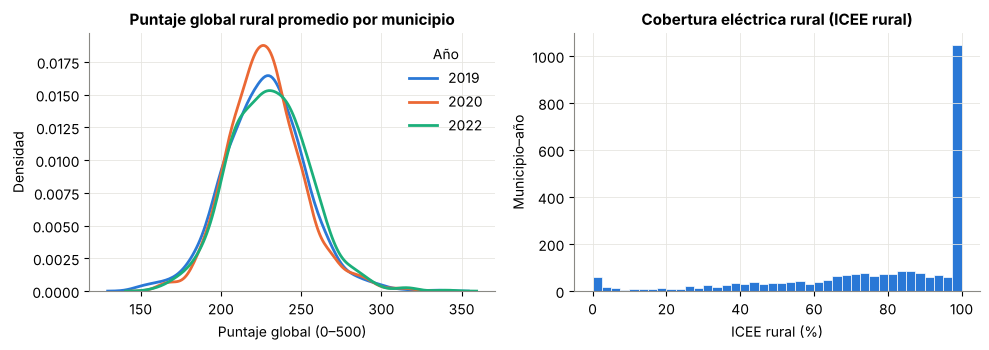

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for anio, col in zip([2019, 2020, 2022], [C1, C2, C3]):
    sns.kdeplot(panel.loc[panel.anio == anio, "punt_global"], ax=ax[0], color=col, lw=2, label=str(anio))
ax[0].set(title="Puntaje global rural promedio por municipio", xlabel="Puntaje global (0–500)", ylabel="Densidad")
ax[0].legend(title="Año")
ax[1].hist(panel["icee_rural"], bins=40, color=C1, edgecolor="white", linewidth=0.5)
ax[1].set(title="Cobertura eléctrica rural (ICEE rural)", xlabel="ICEE rural (%)", ylabel="Municipio–año")
fig.tight_layout(); guardar_fig(fig, "F02_distribuciones"); plt.show()

desc = panel[num_feats].describe(percentiles=[0.25, 0.5, 0.75]).T
desc["asimetría"] = panel[num_feats].skew()
desc = desc.round(2)
guardar_tabla(desc, "T09_descriptivos_panel", index=True)
display(desc)
registrar("objetivo_media", round(panel["punt_global"].mean(), 2))
registrar("objetivo_sd", round(panel["punt_global"].std(), 2))
registrar("objetivo_media_por_anio", {str(k): round(v, 2) for k, v in panel.groupby("anio")["punt_global"].mean().items()})
registrar("objetivo_asimetria", round(panel["punt_global"].skew(), 3))
shapiro_p = stats.normaltest(panel["punt_global"]).pvalue
registrar("objetivo_normaltest_p", float(shapiro_p))
registrar("icee_rural_mediana", round(panel["icee_rural"].median(), 2))
registrar("icee_rural_pct_en_100", round(100 * (panel["icee_rural"] >= 99.999).mean(), 2))
registrar("icee_rural_asimetria", round(panel["icee_rural"].skew(), 3))
grupos_n = panel["grupo_icee"].value_counts().reindex(["Baja (<70 %)", "Media (70–95 %)", "Alta (≥95 %)"])
registrar("grupo_icee_n", {k: int(v) for k, v in grupos_n.items()})
registrar("grupo_icee_pct", {k: round(100 * v / grupos_n.sum(), 2) for k, v in grupos_n.items()})

### 6.2 Variables categóricas: estudiantes rurales frente a urbanos (EDA univariado y bivariado)
Para cada variable de contexto se calcula el porcentaje de estudiantes que cumple la condición, separado por zona.
Sirve para mostrar con datos por qué estas variables se usan como **control**: el campo y la ciudad son muy distintos en ellas.

cole_area_ubicacion,Rural (%),Urbano (%),Diferencia (urbano − rural)
Estrato 0 a 2,81.1,68.1,-13.0
Madre con media completa o más,38.8,66.0,27.2
Tiene internet en el hogar,37.6,75.5,37.9
Tiene computador en el hogar,32.8,63.8,31.0
Colegio oficial,94.3,75.6,-18.7


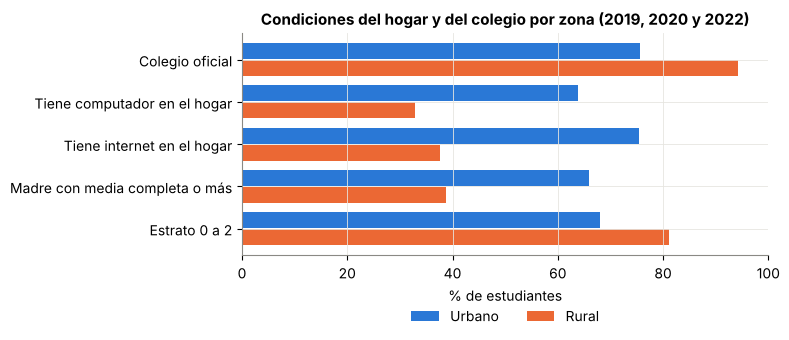

In [16]:
# Cada columna vale 1 (sí), 0 (no) o NaN (sin respuesta); el promedio de una columna 0/1 es la proporción de "sí".
cat_vars = {"estrato_0a2": "Estrato 0 a 2", "madre_media_o_mas": "Madre con media completa o más",
            "internet": "Tiene internet en el hogar", "computador": "Tiene computador en el hogar", "oficial": "Colegio oficial"}
cat_zona = (df.groupby("cole_area_ubicacion")[list(cat_vars)].mean() * 100).T.round(1)   # filas = variable, columnas = zona
cat_zona.index = [cat_vars[v] for v in cat_zona.index]
cat_zona["Diferencia (urbano − rural)"] = (cat_zona["URBANO"] - cat_zona["RURAL"]).round(1)
cat_zona = cat_zona.rename(columns={"RURAL": "Rural (%)", "URBANO": "Urbano (%)"})
guardar_tabla(cat_zona.reset_index().rename(columns={"index": "Variable"}), "T21_categoricas_por_zona")
registrar("categoricas_por_zona", cat_zona.reset_index().rename(columns={"index": "Variable"}).to_dict(orient="records"))

fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(cat_zona))
ax.barh(y + 0.2, cat_zona["Urbano (%)"], height=0.38, color=C1, label="Urbano")
ax.barh(y - 0.2, cat_zona["Rural (%)"], height=0.38, color=C2, label="Rural")
ax.set_yticks(y); ax.set_yticklabels(cat_zona.index)
ax.set(title="Condiciones del hogar y del colegio por zona (2019, 2020 y 2022)", xlabel="% de estudiantes", xlim=(0, 100))
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout(); guardar_fig(fig, "F07_categoricas_por_zona"); plt.show()
display(cat_zona)

### 6.3 Tendencia temporal (2019–2024) y estacionalidad
Saber 11 calendario A se aplica una vez al año y el ICEE es anual: **no hay estacionalidad intra-anual que modelar**. Se analiza la tendencia.

cole_area_ubicacion,RURAL,URBANO,brecha
anio,,,
2019,228.52,257.50,28.98
2020,228.45,256.88,28.44
2022,229.79,259.63,29.84


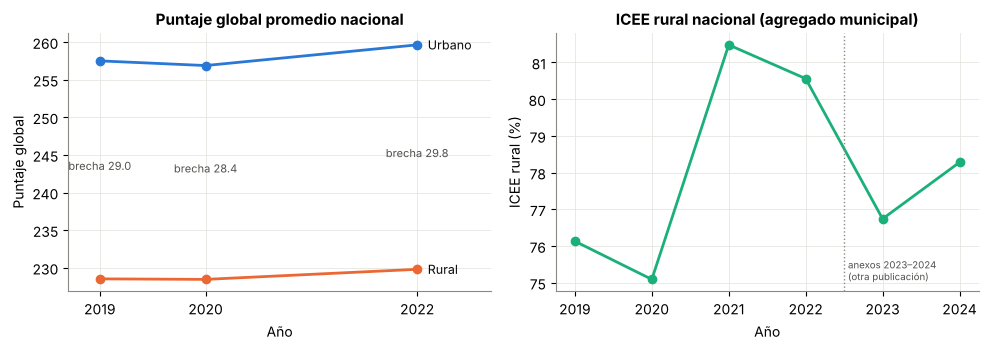

In [17]:
nac = (df.groupby(["anio", "cole_area_ubicacion"])["punt_global"].mean().unstack())
nac["brecha"] = nac["URBANO"] - nac["RURAL"]
nac = nac.round(2)
guardar_tabla(nac.reset_index(), "T10_tendencia_nacional_puntajes")
registrar("nacional_rural_por_anio", {str(k): v for k, v in nac["RURAL"].items()})
registrar("nacional_urbano_por_anio", {str(k): v for k, v in nac["URBANO"].items()})
registrar("brecha_nacional_por_anio", {str(k): v for k, v in nac["brecha"].items()})
icee_nac = (icee.assign(vcs=lambda x: x["vt_rural"] * x["icee_rural"] / 100).groupby("anio")
            .agg(vt=("vt_rural", "sum"), vcs=("vcs", "sum")))
icee_nac["icee_rural_nacional"] = (100 * icee_nac["vcs"] / icee_nac["vt"]).round(2)
guardar_tabla(icee_nac.reset_index(), "T11_tendencia_icee_rural")
registrar("icee_rural_nacional_por_anio", {str(k): v for k, v in icee_nac["icee_rural_nacional"].items()})

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].plot(nac.index, nac["URBANO"], marker="o", color=C1, lw=2, label="Urbano")
ax[0].plot(nac.index, nac["RURAL"], marker="o", color=C2, lw=2, label="Rural")
for x, y1, y2 in zip(nac.index, nac["URBANO"], nac["RURAL"]):
    ax[0].annotate(f"brecha {y1 - y2:.1f}", xy=(x, (y1 + y2) / 2), ha="center", fontsize=8, color="#52514e")
ax[0].text(2022.1, nac.loc[2022, "URBANO"], "Urbano", va="center", fontsize=9, color="#0b0b0b")
ax[0].text(2022.1, nac.loc[2022, "RURAL"], "Rural", va="center", fontsize=9, color="#0b0b0b")
ax[0].set(title="Puntaje global promedio nacional", xlabel="Año", ylabel="Puntaje global", xticks=[2019, 2020, 2022],
          xlim=(2018.7, 2022.7))
ax[1].plot(icee_nac.index, icee_nac["icee_rural_nacional"], marker="o", color=C3, lw=2)
ax[1].axvline(2022.5, color=GRIS, lw=1, ls=":")
ax[1].text(2022.55, ax[1].get_ylim()[0] + 0.3, "anexos 2023–2024\n(otra publicación)", fontsize=7, color="#52514e")
ax[1].set(title="ICEE rural nacional (agregado municipal)", xlabel="Año", ylabel="ICEE rural (%)")
fig.tight_layout(); guardar_fig(fig, "F03_tendencias"); plt.show()
display(nac)

### 6.4 Comparación de alternativas de tratamiento (idea «Compara alternativas» de la guía)
**(a) Municipios con pocos estudiantes.** Un promedio calculado con 3 o 4 estudiantes cambia mucho si uno solo saca un puntaje extremo.
Se comparan dos opciones: **conservar todos** los municipio–año o **excluir** los que tienen menos de 10 estudiantes rurales. Se mira cuánto
cambian la media, la mediana, la desviación estándar y la correlación con el ICEE. La opción que menos cambia los datos es la más segura.

In [18]:
pc = panel_completo.copy()                       # panel antes de excluir municipios con pocos estudiantes
quedan = pc["n_estudiantes"] >= N_MIN            # True = el municipio–año se conserva
filas = []
for nombre, datos in [("Conservar todos", pc), (f"Excluir menos de {N_MIN} estudiantes", pc[quedan])]:
    filas.append({"Alternativa": nombre,
                  "Registros": len(datos),
                  "Media": datos["punt_global"].mean(),
                  "Mediana": datos["punt_global"].median(),
                  "Desv. estándar": datos["punt_global"].std(),
                  "Spearman con ICEE rural": datos["icee_rural"].corr(datos["punt_global"], method="spearman")})
comp_atip = pd.DataFrame(filas).round(3)
guardar_tabla(comp_atip, "T12_comparacion_tratamiento_pocos_estudiantes")
registrar("comp_pocos_estudiantes", comp_atip.to_dict(orient="records"))

# ¿Los que se excluyen son municipios con menos cobertura? Si lo fueran, excluirlos sesgaría el estudio.
# Prueba de Mann–Whitney: compara si dos grupos tienen valores típicamente distintos (no exige normalidad).
excluidos, incluidos = pc.loc[~quedan, "icee_rural"], pc.loc[quedan, "icee_rural"]
p_mw = stats.mannwhitneyu(excluidos, incluidos).pvalue
registrar("excluidos_icee_mediana", round(excluidos.median(), 2))
registrar("incluidos_icee_mediana", round(incluidos.median(), 2))
registrar("excluidos_mannwhitney_p", float(p_mw))
print(f"ICEE rural mediano: excluidos {excluidos.median():.1f} % vs. incluidos {incluidos.median():.1f} % (Mann–Whitney p = {p_mw:.3f})")
print("p > 0,05 → no hay evidencia de que los excluidos tengan distinta cobertura: la exclusión no sesga el ICEE.")
display(comp_atip)

ICEE rural mediano: excluidos 81.6 % vs. incluidos 87.2 % (Mann–Whitney p = 0.098)
p > 0,05 → no hay evidencia de que los excluidos tengan distinta cobertura: la exclusión no sesga el ICEE.


,Alternativa,Registros,Media,Mediana,Desv. estándar,Spearman con ICEE rural
0,Conservar todos,2817,228.121,227.861,24.516,0.289
1,Excluir menos de 10 estudiantes,2627,228.326,227.879,24.180,0.301


**(b) Faltantes: rellenar con la mediana o con municipios parecidos (KNN).** Es el ejemplo que da la guía. Para saber cuál método adivina
mejor, se hace un experimento: se **ocultan a propósito** el 10 % de los valores conocidos de `pct_internet`, se rellenan con cada método y se
compara lo rellenado con el valor real. Gana el método con menor error promedio (MAE) y que menos aplana la distribución.
KNN busca los 5 municipios más parecidos en las demás variables y promedia su valor; por eso antes se ponen todas las variables en la misma
escala (StandardScaler). **Esto es solo una prueba**: el método elegido se aplicará dentro de un Pipeline en el ACA 2.

In [19]:
cov = ["pct_internet", "pct_computador", "pct_estrato_0a2", "pct_madre_media", "pct_oficial", "icee_rural", "pct_viviendas_rurales"]
base = panel[cov].dropna().reset_index(drop=True)          # solo filas completas: así conocemos el valor real
ocultar = RNG.random(len(base)) < 0.10                     # True en ~10 % de las filas, al azar (semilla fija)
con_huecos = base.copy()
con_huecos.loc[ocultar, "pct_internet"] = np.nan            # se "borra" el valor real en esas filas
valor_real = base.loc[ocultar, "pct_internet"]

# Método 1: mediana de la columna
relleno_mediana = con_huecos["pct_internet"].fillna(con_huecos["pct_internet"].median())
# Método 2: KNN con 5 vecinos (en escala estándar y luego de vuelta a porcentaje)
escala = StandardScaler().fit(con_huecos)
knn = KNNImputer(n_neighbors=5).fit_transform(escala.transform(con_huecos))
relleno_knn = pd.Series(escala.inverse_transform(knn)[:, 0])

res = []
for nombre, relleno in [("Mediana", relleno_mediana), ("KNN (5 vecinos)", relleno_knn)]:
    error = (relleno[ocultar] - valor_real).abs()
    res.append({"Método": nombre,
                "Error promedio MAE (p.p.)": error.mean(),
                "Desv. estándar después (p.p.)": relleno.std(),
                "Desv. estándar real (p.p.)": base["pct_internet"].std()})
comp_imp = pd.DataFrame(res).round(2)
guardar_tabla(comp_imp, "T13_comparacion_imputacion")
registrar("comp_imputacion", comp_imp.to_dict(orient="records"))
registrar("comp_imputacion_n_enmascarados", int(ocultar.sum()))
display(comp_imp)

,Método,Error promedio MAE (p.p.),Desv. estándar después (p.p.),Desv. estándar real (p.p.)
0,Mediana,17.27,21.27,22.26
1,KNN (5 vecinos),11.75,21.89,22.26


### 6.5 Relación entre cobertura eléctrica y puntaje rural (EDA bivariado)

,count,mean,median,std
grupo_icee,,,,
Baja (<70 %),791,217.75,217.17,18.46
Media (70–95 %),733,231.46,231.73,21.21
Alta (≥95 %),1103,233.82,234.29,27.07


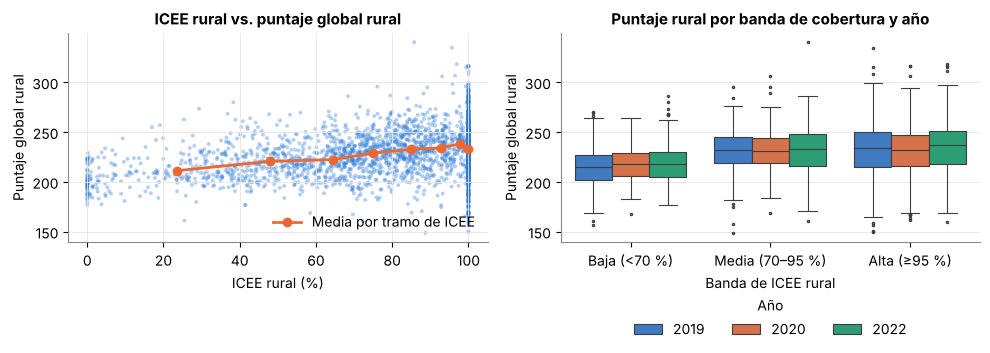

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
ax[0].scatter(panel["icee_rural"], panel["punt_global"], s=8, alpha=0.35, color=C1, edgecolor="none")
tramos = pd.cut(panel["icee_rural"], bins=[0, 40, 55, 70, 80, 90, 95, 99.999, 100.01], include_lowest=True)
media_tramo = panel.groupby(tramos, observed=True).agg(x=("icee_rural", "median"), y=("punt_global", "mean"))
ax[0].plot(media_tramo["x"], media_tramo["y"], color=C2, lw=2, marker="o", label="Media por tramo de ICEE")
ax[0].set(title="ICEE rural vs. puntaje global rural", xlabel="ICEE rural (%)", ylabel="Puntaje global rural")
ax[0].legend(loc="lower right")
orden = ["Baja (<70 %)", "Media (70–95 %)", "Alta (≥95 %)"]
sns.boxplot(data=panel, x="grupo_icee", y="punt_global", order=orden, hue="anio", palette=[C1, C2, C3],
            ax=ax[1], linewidth=0.8, fliersize=1.5)
ax[1].set(title="Puntaje rural por banda de cobertura y año", xlabel="Banda de ICEE rural", ylabel="Puntaje global rural")
ax[1].legend(title="Año", ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
fig.tight_layout(); guardar_fig(fig, "F04_relacion_icee_puntaje"); plt.show()

med_grupo = panel.groupby("grupo_icee", observed=True)["punt_global"].agg(["count", "mean", "median", "std"]).reindex(orden).round(2)
guardar_tabla(med_grupo.reset_index(), "T14_puntaje_por_banda_icee")
registrar("puntaje_por_banda", {k: {"n": int(r["count"]), "media": r["mean"], "mediana": r["median"]} for k, r in med_grupo.iterrows()})
diferencia = med_grupo.loc["Alta (≥95 %)", "mean"] - med_grupo.loc["Baja (<70 %)", "mean"]
registrar("diferencia_alta_baja", round(diferencia, 2))
registrar("diferencia_alta_baja_en_sd", round(diferencia / panel["punt_global"].std(), 3))
display(med_grupo)

### 6.6 Puntaje por área de Saber 11 según la banda de cobertura
¿La diferencia entre bandas se concentra en alguna área? Se calcula el promedio de cada área por banda y la diferencia Alta − Baja.

grupo_icee,Baja (<70 %),Media (70–95 %),Alta (≥95 %),Diferencia Alta − Baja
Matemáticas,44.55,47.74,48.00,3.45
Sociales y ciudadanas,41.02,43.69,44.36,3.34
Inglés,41.23,43.44,44.40,3.17
Lectura crítica,46.15,48.67,49.21,3.06
Ciencias naturales,43.26,46.03,46.28,3.02


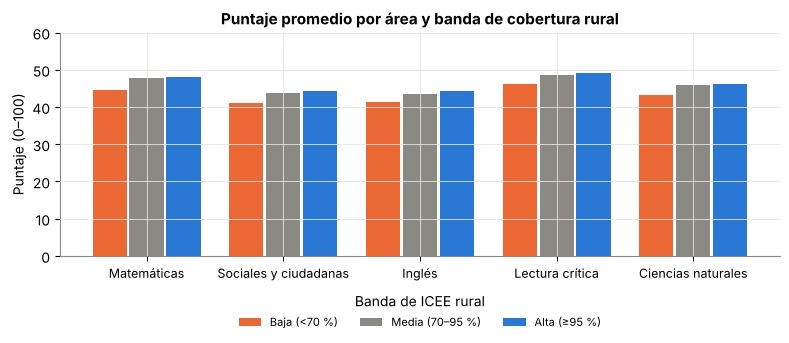

In [21]:
areas = {"punt_lectura": "Lectura crítica", "punt_matematicas": "Matemáticas", "punt_naturales": "Ciencias naturales",
         "punt_sociales": "Sociales y ciudadanas", "punt_ingles": "Inglés"}
area_banda = panel.groupby("grupo_icee", observed=True)[list(areas)].mean().reindex(orden).T.round(2)
area_banda.index = [areas[a] for a in area_banda.index]
area_banda["Diferencia Alta − Baja"] = (area_banda["Alta (≥95 %)"] - area_banda["Baja (<70 %)"]).round(2)
area_banda = area_banda.sort_values("Diferencia Alta − Baja", ascending=False)
guardar_tabla(area_banda.reset_index().rename(columns={"index": "Área"}), "T22_areas_por_banda")
registrar("areas_por_banda", area_banda.reset_index().rename(columns={"index": "Área"}).to_dict(orient="records"))

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(area_banda))
for k, (banda, col) in enumerate(zip(orden, [C2, GRIS, C1])):
    ax.bar(x + (k - 1) * 0.27, area_banda[banda], width=0.25, color=col, label=banda)
ax.set_xticks(x); ax.set_xticklabels(area_banda.index, fontsize=9)
ax.set(title="Puntaje promedio por área y banda de cobertura rural", ylabel="Puntaje (0–100)", ylim=(0, 60))
ax.legend(title="Banda de ICEE rural", ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.12))
fig.tight_layout(); guardar_fig(fig, "F08_areas_por_banda"); plt.show()
display(area_banda)

### 6.7 Correlaciones de Pearson y Spearman (EDA multivariado)
**Pearson** mide relación en línea recta y es sensible a valores extremos. **Spearman** ordena los datos de menor a mayor y mide si
cuando uno sube el otro también tiende a subir; por eso funciona mejor con el ICEE, que está muy amontonado en 100 %.

,Pearson,Spearman,p (Spearman)
% computador,0.544,0.464,1.072198e-140
% internet,0.494,0.418,1.618406e-111
ICEE rural,0.322,0.301,4.536724e-56
% madre media+,0.324,0.189,1.209518e-22
% estrato 0–2,-0.152,0.137,1.749347e-12
% viv. rurales,-0.104,-0.032,1.041863e-01
Brecha ICEE u–r,-0.243,-0.249,2.413646e-38
ln VSS rural,-0.211,-0.264,4.693173e-43
% oficial,-0.438,-0.316,6.342222e-62


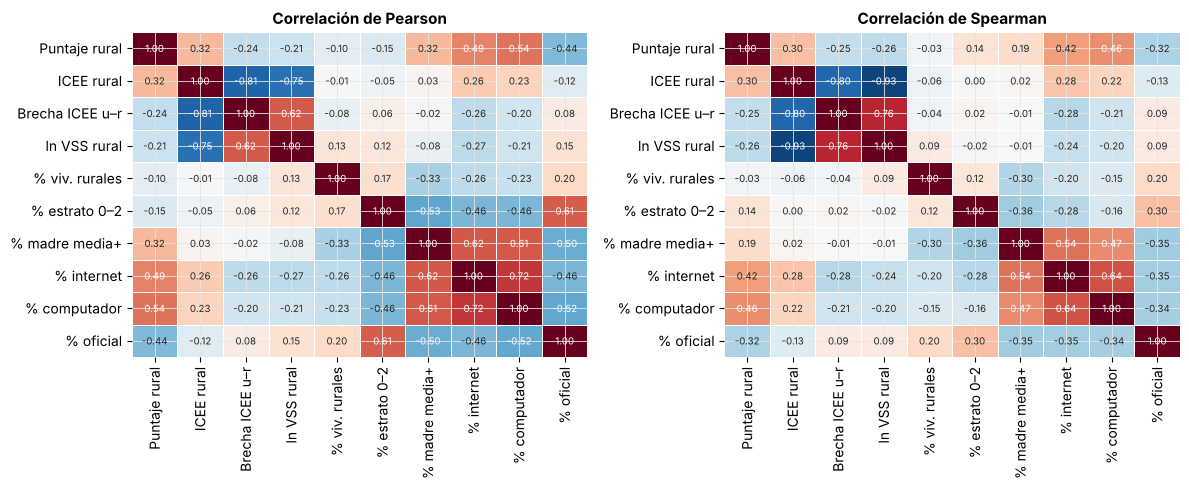

In [22]:
corr_vars = ["punt_global", "icee_rural", "brecha_icee_urb_rur", "log_vss_rural", "pct_viviendas_rurales", "pct_estrato_0a2",
             "pct_madre_media", "pct_internet", "pct_computador", "pct_oficial"]
etq = {"punt_global": "Puntaje rural", "icee_rural": "ICEE rural", "brecha_icee_urb_rur": "Brecha ICEE u–r",
       "log_vss_rural": "ln VSS rural", "pct_viviendas_rurales": "% viv. rurales", "pct_estrato_0a2": "% estrato 0–2",
       "pct_madre_media": "% madre media+", "pct_internet": "% internet", "pct_computador": "% computador",
       "pct_oficial": "% oficial"}
pear = panel[corr_vars].corr(method="pearson")
spear = panel[corr_vars].corr(method="spearman")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for eje, matriz, nombre in [(ax[0], pear, "Pearson"), (ax[1], spear, "Spearman")]:
    sns.heatmap(matriz.rename(index=etq, columns=etq), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
                ax=eje, cbar=False, annot_kws={"size": 7}, linewidths=0.5, linecolor="white")
    eje.set_title(f"Correlación de {nombre}")
fig.tight_layout(); guardar_fig(fig, "F05_correlaciones"); plt.show()
corr_obj = pd.DataFrame({"Pearson": pear["punt_global"], "Spearman": spear["punt_global"]}).drop("punt_global").round(3)
corr_obj["p (Spearman)"] = [stats.spearmanr(panel[v], panel["punt_global"], nan_policy="omit").pvalue for v in corr_obj.index]
corr_obj = corr_obj.rename(index=etq).sort_values("Spearman", ascending=False)
guardar_tabla(corr_obj.reset_index().rename(columns={"index": "Variable"}), "T15_correlaciones_con_objetivo")
registrar("pearson_icee_puntaje", round(pear.loc["icee_rural", "punt_global"], 3))
registrar("spearman_icee_puntaje", round(spear.loc["icee_rural", "punt_global"], 3))
registrar("spearman_internet_icee", round(spear.loc["icee_rural", "pct_internet"], 3))
registrar("spearman_madre_puntaje", round(spear.loc["pct_madre_media", "punt_global"], 3))
registrar("spearman_internet_puntaje", round(spear.loc["pct_internet", "punt_global"], 3))
registrar("correlaciones_objetivo", corr_obj.reset_index().rename(columns={"index": "Variable"}).to_dict(orient="records"))
display(corr_obj)

### 6.8 Prueba chi-cuadrado y V de Cramér (variables categóricas)
La correlación sirve para números; para **categorías** se usa la prueba chi-cuadrado: compara la tabla de conteos observada con la que
esperaríamos si las dos variables no tuvieran nada que ver. Si p < 0,05 hay asociación. Como con muchos datos casi todo sale
significativo, se reporta también la **V de Cramér**, que mide la fuerza de 0 (nada) a 1 (total): ~0,1 débil, ~0,3 moderada, ≥0,5 fuerte.
Cruces: (1) estudiantes rurales: ¿tener internet se asocia con la banda de cobertura de su municipio? (2) municipio–año: banda × región.

In [23]:
def chi_cuadrado(tabla, descripcion):
    chi2, p, gl, _ = stats.chi2_contingency(tabla)
    n = tabla.to_numpy().sum()
    v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))          # V de Cramér
    return {"Cruce": descripcion, "n": int(n), "Chi-cuadrado": round(chi2, 1), "gl": int(gl),
            "p": "< 0,001" if p < 0.001 else round(p, 3), "V de Cramér": round(v, 3)}

# (1) Estudiante rural × banda del municipio: se le pega a cada estudiante la banda de su municipio y año
rurales = df[df["rural"] == 1].merge(panel[["cod_mpio", "anio", "grupo_icee"]], on=["cod_mpio", "anio"], how="inner")
tabla_internet = pd.crosstab(rurales["grupo_icee"], rurales["fami_tieneinternet"])   # filas: banda; columnas: Si / No
# (2) Municipio–año: banda × región
tabla_region = pd.crosstab(panel["grupo_icee"], panel["region"])
chi_tab = pd.DataFrame([chi_cuadrado(tabla_internet, "Internet en el hogar (estudiante rural) × banda de ICEE"),
                        chi_cuadrado(tabla_region, "Banda de ICEE × región (municipio–año)")])
pct_internet_banda = (100 * pd.crosstab(rurales["grupo_icee"], rurales["fami_tieneinternet"], normalize="index")).round(1)
guardar_tabla(chi_tab, "T23_chi_cuadrado")
registrar("chi_cuadrado", chi_tab.to_dict(orient="records"))
registrar("pct_internet_por_banda", {str(k): v for k, v in pct_internet_banda["Si"].items()})
display(chi_tab); display(pct_internet_banda); display(tabla_region)

,Cruce,n,Chi-cuadrado,gl,p,V de Cramér
0,Internet en el hogar (estudiante rural) × banda de ICEE,230609,8821.3,2,"< 0,001",0.196
1,Banda de ICEE × región (municipio–año),2627,975.2,8,"< 0,001",0.431


fami_tieneinternet,No,Si
grupo_icee,,
Baja (<70 %),74.3,25.7
Media (70–95 %),65.2,34.8
Alta (≥95 %),52.5,47.5


region,Amazonía,Andina,Caribe,Orinoquía,Pacífica
grupo_icee,,,,,
Baja (<70 %),85,131,394,71,110
Media (70–95 %),27,458,70,34,144
Alta (≥95 %),12,782,46,26,237


### 6.9 Multicolinealidad (VIF)
Si dos variables explicativas dicen casi lo mismo, un modelo no puede separar el efecto de cada una. El VIF lo mide: para cada variable se
hace una regresión con las demás y se calcula VIF = 1 / (1 − R²). VIF ≤ 5 aceptable; > 5 alerta; > 10 problema serio.

In [24]:
vif_vars = ["icee_rural", "brecha_icee_urb_rur", "log_vss_rural", "pct_viviendas_rurales", "pct_estrato_0a2",
            "pct_madre_media", "pct_internet", "pct_computador", "pct_oficial"]
X = panel[vif_vars].dropna()
vif_valores = {}
for var in vif_vars:
    otras = X.drop(columns=var)                                   # todas menos la variable que se evalúa
    r2 = LinearRegression().fit(otras, X[var]).score(otras, X[var])   # ¿qué tan bien la explican las demás?
    vif_valores[etq[var]] = 1 / (1 - r2)
vif_tab = pd.Series(vif_valores).round(2).to_frame("VIF").sort_values("VIF", ascending=False)
vif_tab["Diagnóstico"] = np.select([vif_tab["VIF"] > 10, vif_tab["VIF"] > 5], ["Crítico (>10)", "Alerta (>5)"], "Aceptable (≤5)")
guardar_tabla(vif_tab.reset_index().rename(columns={"index": "Variable"}), "T16_vif")
registrar("vif", vif_tab["VIF"].to_dict())
registrar("vif_max", float(vif_tab["VIF"].max()))
registrar("vif_max_var", vif_tab["VIF"].idxmax())
display(vif_tab)

,VIF,Diagnóstico
ICEE rural,4.30,Aceptable (≤5)
Brecha ICEE u–r,3.05,Aceptable (≤5)
% internet,2.48,Aceptable (≤5)
% computador,2.44,Aceptable (≤5)
ln VSS rural,2.44,Aceptable (≤5)
% madre media+,2.17,Aceptable (≤5)
% oficial,1.83,Aceptable (≤5)
% estrato 0–2,1.81,Aceptable (≤5)
% viv. rurales,1.20,Aceptable (≤5)


### 6.10 Desbalance
El enfoque no es de clasificación, así que no hay desbalance de clases que corregir. Sí hay **desbalance de la variable explicativa**:
muchos municipios tienen cobertura rural alta y menos tienen cobertura baja. Se reporta porque afecta las comparaciones del ACA 3.

In [25]:
desb = panel.groupby(["anio", "grupo_icee"], observed=True).size().unstack().reindex(columns=orden)
desb_pct = (100 * desb.div(desb.sum(axis=1), axis=0)).round(1)
guardar_tabla(desb.reset_index(), "T17_desbalance_bandas_icee")
display(desb); display(desb_pct)

grupo_icee,Baja (<70 %),Media (70–95 %),Alta (≥95 %)
anio,,,
2019,266,270,334
2020,277,243,345
2022,248,220,424


grupo_icee,Baja (<70 %),Media (70–95 %),Alta (≥95 %)
anio,,,
2019,30.6,31.0,38.4
2020,32.0,28.1,39.9
2022,27.8,24.7,47.5


### 6.11 ¿El hallazgo se sostiene? (idea «Demuestra que se sostiene» de la guía)
Se repite la correlación de Spearman en subgrupos: por **año**, por **región**, con el **ICEE sin transferencias** y **dentro de grupos de
municipios con nivel educativo parecido** (tercios del % de madres con media o más). Si dentro de cada grupo parecido la relación sigue
siendo positiva, no se explica solo porque los municipios con más luz sean también los más educados.
Cada correlación lleva un intervalo de confianza del 95 % por **bootstrap**: se toma una muestra al azar con reemplazo del mismo tamaño,
se calcula la correlación, se repite 2.000 veces y se toman los percentiles 2,5 y 97,5. Si el intervalo no toca el cero, la relación es firme.

,Subgrupo,Tipo,n,rho,IC95 inf,IC95 sup
0,Total,Total,2627,0.301,0.265,0.338
1,2019,Año,870,0.325,0.259,0.387
2,2020,Año,865,0.283,0.217,0.349
3,2022,Año,892,0.281,0.218,0.344
4,Amazonía,Región,124,0.312,0.127,0.478
5,Andina,Región,1371,0.053,-0.000,0.104
6,Caribe,Región,510,0.338,0.258,0.409
7,Orinoquía,Región,131,0.431,0.260,0.581
8,Pacífica,Región,491,-0.012,-0.101,0.078
9,ICEE sin transferencias,Sensibilidad,2627,0.318,0.282,0.356


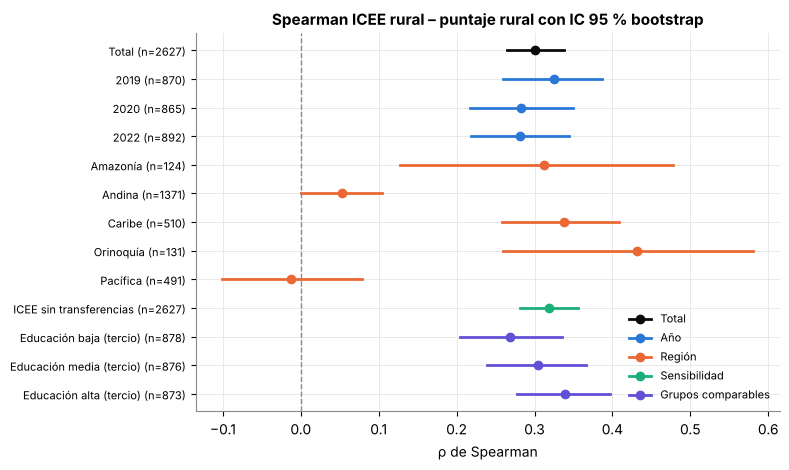

In [26]:
def spearman_con_intervalo(x, y, repeticiones=2000):
    x, y = np.asarray(x), np.asarray(y)
    rho = stats.spearmanr(x, y).statistic
    rhos_bootstrap = []
    for _ in range(repeticiones):
        i = RNG.integers(0, len(x), len(x))                   # índices al azar con reemplazo
        rhos_bootstrap.append(stats.spearmanr(x[i], y[i]).statistic)
    return rho, np.nanpercentile(rhos_bootstrap, 2.5), np.nanpercentile(rhos_bootstrap, 97.5)

def fila_robustez(nombre, tipo, datos, col_x="icee_rural"):
    rho, inf, sup = spearman_con_intervalo(datos[col_x], datos["punt_global"])
    return {"Subgrupo": nombre, "Tipo": tipo, "n": len(datos), "rho": rho, "IC95 inf": inf, "IC95 sup": sup}

rob = [fila_robustez("Total", "Total", panel)]
for anio, grupo in panel.groupby("anio"):
    rob.append(fila_robustez(str(anio), "Año", grupo))
for region, grupo in panel.groupby("region"):
    rob.append(fila_robustez(region, "Región", grupo))
# Sensibilidad 1: ICEE antes de transferencias (hoja alternativa de la UPME, 2019–2022)
sin = icee_1922_sin.rename(columns={"Divipola": "cod", "Año": "anio", "ICEE Rural": "icee_rural_sin"})
sin["cod_mpio"] = sin["cod"].astype(str).str.zfill(5)
sin["icee_rural_sin"] = 100 * sin["icee_rural_sin"]
con_sin = panel.merge(sin[["cod_mpio", "anio", "icee_rural_sin"]], on=["cod_mpio", "anio"], how="inner")
rob.append(fila_robustez("ICEE sin transferencias", "Sensibilidad", con_sin, col_x="icee_rural_sin"))
# Sensibilidad 2: dentro de tercios de nivel educativo de las madres (municipios comparables)
panel["tercio_educativo"] = pd.qcut(panel["pct_madre_media"], 3, labels=["Educación baja", "Educación media", "Educación alta"])
for tercio, grupo in panel.groupby("tercio_educativo", observed=True):
    rob.append(fila_robustez(f"{tercio} (tercio)", "Grupos comparables", grupo))
rob = pd.DataFrame(rob).round(3)
guardar_tabla(rob, "T18_robustez_spearman")
registrar("robustez", rob.to_dict(orient="records"))

fig, ax = plt.subplots(figsize=(8, 4.8))
ypos = np.arange(len(rob))[::-1]
colores = {"Total": "#0b0b0b", "Año": C1, "Región": C2, "Sensibilidad": C3, "Grupos comparables": "#6250d6"}
for yy, (_, r) in zip(ypos, rob.iterrows()):
    ax.plot([r["IC95 inf"], r["IC95 sup"]], [yy, yy], color=colores[r["Tipo"]], lw=2)
    ax.plot(r["rho"], yy, "o", color=colores[r["Tipo"]], ms=6)
ax.axvline(0, color=GRIS, lw=1, ls="--")
ax.set_yticks(ypos); ax.set_yticklabels([f"{s} (n={n})" for s, n in zip(rob["Subgrupo"], rob["n"])], fontsize=8)
ax.set(title="Spearman ICEE rural – puntaje rural con IC 95 % bootstrap", xlabel="ρ de Spearman")
from matplotlib.lines import Line2D
ax.legend(handles=[Line2D([0], [0], color=v, lw=2, marker="o", label=k) for k, v in colores.items()], loc="lower right", fontsize=8)
fig.tight_layout(); guardar_fig(fig, "F06_robustez"); plt.show()
display(rob)

### 6.12 ¿Cuánta variación del puntaje acompaña al ICEE? (insumo del objetivo 3)
Se ajustan regresiones lineales simples y se mira su **R²** (porcentaje de la variación del puntaje que el modelo reproduce).
Comparando el modelo con controles **con** y **sin** ICEE se obtiene cuánto agrega el ICEE (ΔR²). Es exploratorio: la prueba formal va en el ACA 3.

In [27]:
controles = ["pct_estrato_0a2", "pct_madre_media", "pct_oficial", "pct_viviendas_rurales"]
datos = panel[["punt_global", "icee_rural", "anio"] + controles].dropna()
anio_dummies = pd.get_dummies(datos["anio"], prefix="anio", drop_first=True, dtype=float)   # 2020 y 2022 frente a 2019
y_obj = datos["punt_global"]
def r2_de(columnas_X):
    X = pd.concat([datos[columnas_X], anio_dummies], axis=1)
    return LinearRegression().fit(X, y_obj).score(X, y_obj)
r2_icee = r2_de(["icee_rural"])
r2_ctrl = r2_de(controles)
r2_full = r2_de(controles + ["icee_rural"])
var_tab = pd.DataFrame([
    {"Modelo exploratorio": "Año + ICEE rural", "R²": r2_icee},
    {"Modelo exploratorio": "Año + controles socioeconómicos", "R²": r2_ctrl},
    {"Modelo exploratorio": "Año + controles + ICEE rural", "R²": r2_full},
    {"Modelo exploratorio": "ΔR² que agrega el ICEE rural sobre los controles", "R²": r2_full - r2_ctrl},
]).round(4)
guardar_tabla(var_tab, "T19_varianza_exploratoria")
registrar("varianza", var_tab.to_dict(orient="records"))
display(var_tab)

,Modelo exploratorio,R²
0,Año + ICEE rural,0.1046
1,Año + controles socioeconómicos,0.2462
2,Año + controles + ICEE rural,0.3191
3,ΔR² que agrega el ICEE rural sobre los controles,0.0730


## 7. Hallazgos traducidos a decisiones (idea «Tradúcelo a decisiones» de la guía)

In [28]:
rob_i = rob.set_index("Subgrupo")
tercios = rob[rob["Tipo"] == "Grupos comparables"]
hallazgos = pd.DataFrame([
    {"Hallazgo": f"Los municipios con cobertura rural alta (≥95 %) superan en {CIFRAS['diferencia_alta_baja']:.1f} puntos "
                 f"({CIFRAS['diferencia_alta_baja_en_sd']:.2f} desviaciones estándar) a los de cobertura baja (<70 %) en el puntaje global rural.",
     "Decisión que sugiere": "Usar la banda de ICEE rural como criterio de focalización de programas de refuerzo académico rural."},
    {"Hallazgo": f"La asociación (ρ = {rob_i.loc['Total', 'rho']:.2f}) se repite en 2019, 2020 y 2022 y sigue siendo positiva dentro de grupos "
                 f"de municipios con nivel educativo parecido (ρ entre {tercios['rho'].min():.2f} y {tercios['rho'].max():.2f}); "
                 f"el ICEE agrega {100 * (r2_full - r2_ctrl):.1f} puntos porcentuales de R² sobre los controles.",
     "Decisión que sugiere": "Tratar la electrificación rural como componente de la política educativa y someter la relación a prueba formal en el ACA 3."},
    {"Hallazgo": f"La relación no es homogénea: es clara en Orinoquía (ρ = {rob_i.loc['Orinoquía', 'rho']:.2f}), Caribe "
                 f"(ρ = {rob_i.loc['Caribe', 'rho']:.2f}) y Amazonía (ρ = {rob_i.loc['Amazonía', 'rho']:.2f}), y prácticamente nula en "
                 f"Andina (ρ = {rob_i.loc['Andina', 'rho']:.2f}) y Pacífica (ρ = {rob_i.loc['Pacífica', 'rho']:.2f}).",
     "Decisión que sugiere": "Priorizar inversiones conjuntas energía–educación en Caribe, Orinoquía y Amazonía; en el Pacífico indagar otras barreras."},
])
registrar("hallazgos", hallazgos.to_dict(orient="records"))
guardar_tabla(hallazgos, "T20_hallazgos_decisiones")
display(hallazgos)

,Hallazgo,Decisión que sugiere
0,Los municipios con cobertura rural alta (≥95 %) superan en 16.1 puntos (0.67 desviaciones estándar) a los de cobertura baja (<70 %) en el puntaje global rural.,Usar la banda de ICEE rural como criterio de focalización de programas de refuerzo académico rural.
1,"La asociación (ρ = 0.30) se repite en 2019, 2020 y 2022 y sigue siendo positiva dentro de grupos de municipios con nivel educativo parecido (ρ entre 0.27 y 0.34); el ICEE agrega 7.3 puntos porcentuales de R² sobre los controles.",Tratar la electrificación rural como componente de la política educativa y someter la relación a prueba formal en el ACA 3.
2,"La relación no es homogénea: es clara en Orinoquía (ρ = 0.43), Caribe (ρ = 0.34) y Amazonía (ρ = 0.31), y prácticamente nula en Andina (ρ = 0.05) y Pacífica (ρ = -0.01).","Priorizar inversiones conjuntas energía–educación en Caribe, Orinoquía y Amazonía; en el Pacífico indagar otras barreras."


## 8. Cierre: salidas para el documento y para el ACA 2

In [29]:
CIFRAS["fecha_ejecucion"] = dt.datetime.now().isoformat(timespec="seconds")
CIFRAS["semilla"] = SEED
CIFRAS["tiempo_ejecucion_s"] = round(time.time() - T0, 1)
CIFRAS["maquina"] = "Google Colab (CPU)" if EN_COLAB else f"{platform.system()} {platform.machine()} (CPU)"
with open(TAB / "cifras.json", "w", encoding="utf-8") as f:
    json.dump(CIFRAS, f, ensure_ascii=False, indent=2, default=str)

# Registro de la corrida (una fila por ejecución): fecha, modelo, parámetros, semilla y métricas
exp_path = ROOT / "results/experiments.csv"
fila = pd.DataFrame([{
    "fecha": CIFRAS["fecha_ejecucion"], "aca": "ACA1", "modelo": "Sin modelo (ETL + EDA exploratorio)",
    "parametros": json.dumps({"n_min_estudiantes": N_MIN, "bandas_icee": [70, 95], "bootstrap": 2000,
                              "icee_hoja": "con transferencias", "modo_adquisicion": MODO_ADQUISICION}, ensure_ascii=False),
    "semilla": SEED, "entorno": CIFRAS["maquina"], "tiempo_s": CIFRAS["tiempo_ejecucion_s"],
    "metricas": json.dumps({"panel_filas": CIFRAS["panel_filas"], "spearman_icee_puntaje": CIFRAS["spearman_icee_puntaje"],
                            "delta_r2_icee": round(float(r2_full - r2_ctrl), 4)}, ensure_ascii=False)}])
fila.to_csv(exp_path, mode="a", header=not exp_path.exists(), index=False, encoding="utf-8")

# En Colab: versiones exactas de las librerías (guía CUN: !pip freeze > requirements.txt).
# Descargue el archivo desde el panel Archivos y reemplace requirements.txt en el repositorio.
if EN_COLAB:
    with open(ROOT / "requirements.txt", "w") as f:
        subprocess.run([sys.executable, "-m", "pip", "freeze"], stdout=f, check=True)
    print("requirements.txt actualizado con las versiones exactas de Colab")
print("Tablas:", sorted(p.name for p in TAB.glob("*.csv")))
print("Figuras:", sorted(p.name for p in FIG.glob("*.png")))
print("Panel final:", PROCESSED / "panel_municipal_rural_2019_2022.csv", panel.shape)

Tablas: ['T01_ficha_dataset.csv', 'T02_diccionario_datos_crudos.csv', 'T03_conteos_etl_icfes.csv', 'T04_faltantes_estudiante.csv', 'T05_conteos_etl_icee.csv', 'T06_conteos_integracion.csv', 'T07_resumen_conteos_etl.csv', 'T08_diccionario_panel.csv', 'T09_descriptivos_panel.csv', 'T10_tendencia_nacional_puntajes.csv', 'T11_tendencia_icee_rural.csv', 'T12_comparacion_tratamiento_pocos_estudiantes.csv', 'T13_comparacion_imputacion.csv', 'T14_puntaje_por_banda_icee.csv', 'T15_correlaciones_con_objetivo.csv', 'T16_vif.csv', 'T17_desbalance_bandas_icee.csv', 'T18_robustez_spearman.csv', 'T19_varianza_exploratoria.csv', 'T20_hallazgos_decisiones.csv', 'T21_categoricas_por_zona.csv', 'T22_areas_por_banda.csv', 'T23_chi_cuadrado.csv']
Figuras: ['F02_distribuciones.png', 'F03_tendencias.png', 'F04_relacion_icee_puntaje.png', 'F05_correlaciones.png', 'F06_robustez.png', 'F07_categoricas_por_zona.png', 'F08_areas_por_banda.png']
Panel final: /home/claude/energia-rural-saber11/data/processed/panel_